# DSA4213 Assignment 1: complete experimental workflow

This notebook is the executable source for Parts I-III and the originally supplementary experiments. Prepare the dependencies and `data/glove.6B/glove.6B.100d.txt`, save the notebook, restart the kernel and run all cells from the project root. GloVe is checked before training; IMDb is loaded through Hugging Face (network or cache required).

Running all cells retrains the models and overwrites generated results. It does not silently reuse old supplementary runs. Output files retain their original names for comparison with the submitted report. Cell outputs were cleared during consolidation; the supplied JSON/PDF files are historical measurements, not evidence that this revised notebook has already been fully retrained.

| Report evidence | Notebook section | Saved evidence |
|---|---|---|
| Part I / Table 1 | Original LMs, trigram grid/cost, Transformer budget | `results/*_results.json`, `results/supplementary/trigram_grid*.json`, `training/transformer_budget40_*` |
| Part II / Appendix A | Frozen inputs, repeated seeds, random-frozen control | `part2_summary.json`, `supplementary/multiseed.json`, `supplementary/training/*` |
| Generated text | Matched generation comparison | `supplementary/generation.json` |
| Part III / Appendix D | Contextual features, baselines, paired statistics, error groups | `part3/*`, `supplementary/classification.json`, `test_predictions.npz`, `error_analysis.json` |
| Cost/coverage / Appendix B | Embedding diagnostics and runtime summary | `supplementary/embedding_diagnostics.json`, `timing.json`, `environment.json` |
| Reproduction audit | Data fingerprints, result checks, run provenance | `data/current_run_manifest.json`, `results/run_provenance.json` |

Paths in the table are relative to `results/` unless stated otherwise. Stable section titles and cell IDs identify the producer of each result. Historical supplementary analyses remain exploratory despite integration into the execution order.

## Environment

Install once in the intended environment: `python -m pip install -r requirements.txt`. Select that environment as the notebook kernel. The recorded neural runs used Python 3.12.13 and PyTorch 2.14.0+cu130. Review the CUDA wheel separately for your machine. The next cell imports all base dependencies; supplementary imports are explicit in the execution-contract cell.

In [1]:
from pathlib import Path
import json
from datasets import load_dataset
from collections import Counter
import html
import re
import time
import math
import random
from itertools import islice
from statistics import median
import platform
import pickle
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import gensim
from gensim.models import Word2Vec
import zlib
import numpy as np
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

In [2]:
SEED = 42
PROJECT_DIR = Path.cwd() 
DATA_DIR = PROJECT_DIR / 'data'
RESULTS_DIR = PROJECT_DIR / 'results'
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MAX_VOCAB = 20000
MIN_COUNT = 2
TOKEN_PATTERN = r"[a-z]+(?:'[a-z]+)*|\d+|[^\w\s]"
ALPHA = 0.1
PROMPTS = ['the movie was', 'i really enjoyed', 'the story begins with']
MAX_NEW_TOKENS = 40
NEURAL_CONFIG = {
    'seed': SEED, 'embedding_dim': 100, 'hidden_dim': 256,
    'sequence_length': 128, 'batch_size': 16, 'epochs': 20,
    'learning_rate': 0.001, 'gradient_clip': 1.0,
    'tol': 1e-4, 'patience': 3,
}
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


EMBED_DIM = NEURAL_CONFIG['embedding_dim']
EMBED_DIR = DATA_DIR / 'embeddings'
EMBED_DIR.mkdir(exist_ok=True)
GLOVE_PATH = DATA_DIR / 'glove.6B' / 'glove.6B.100d.txt'

### Execution contract and traceability

Run this notebook from the project root, from top to bottom. Every experiment runs again, including seeds 43/44; existing JSON files never skip training. Back up results before rerunning. Historical supplementary results remain exploratory because their design followed inspection of the original test results. Integrating their code does not make them confirmatory.

In [3]:
import hashlib
import importlib.metadata
from datetime import datetime, timezone
from scipy.stats import binomtest
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer

ROOT = PROJECT_DIR
SUPPLEMENTARY_DIR = RESULTS_DIR / 'supplementary'
EXTRA_TRAINING_DIR = SUPPLEMENTARY_DIR / 'training'
EXTRA_TRAINING_DIR.mkdir(parents=True, exist_ok=True)
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat()
# Used by the original supplementary experiments; make the setting explicit.
torch.set_num_threads(4)

def read(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def save(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')

assert (ROOT / 'Assignment.ipynb').is_file(), 'Start the kernel in the _Code directory.'
if not GLOVE_PATH.is_file():
    raise FileNotFoundError(f'Prepare GloVe 6B 100d before training: {GLOVE_PATH}')
print('Run started:', RUN_STARTED_UTC)
print('Device:', device, '| GloVe:', GLOVE_PATH)

Run started: 2026-10-14T16:16:03.459418+00:00
Device: cuda | GloVe: c:\personal information\dai\study\nus\DSA4213\DSA4213_Assignment1_Code\data\glove.6B\glove.6B.100d.txt


Neural models use a 20-epoch cap with validation early stopping (tolerance 0.0001, patience 3). Test evaluation restores the checkpoint with the absolute lowest validation cross-entropy. Skip-gram pretraining uses five epochs.

## 2. Shared data preparation
Download IMDb once, construct the fixed splits, and reuse the same data throughout.


In [4]:
dataset = load_dataset('stanfordnlp/imdb')
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [5]:
example = dataset["train"][0]

print("text:")
print(example["text"][:500])

print("\nlabel:", example["label"])

text:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

label: 0


In [6]:
def text_key(text):
    return " ".join(text.lower().split())

def remove_duplicates(data, excluded=()):
    seen = set(excluded)
    indices = []
    for i, text in enumerate(data['text']):
        key = text_key(text)
        if key not in seen:
            indices.append(i)
            seen.add(key)
    return data.select(indices)

test_pool = remove_duplicates(dataset['test'])
test_keys = {text_key(text) for text in test_pool['text']}
train_pool = remove_duplicates(dataset['train'], excluded=test_keys)

selected = train_pool.train_test_split(
    train_size=6000, stratify_by_column='label', seed=SEED)['train']
split = selected.train_test_split(
    test_size=1000, stratify_by_column='label', seed=SEED)
train_data, val_data = split['train'], split['test']
test_data = test_pool.train_test_split(
    test_size=1000, stratify_by_column='label', seed=SEED)['test']

In [7]:
splits = {
    'train': train_data,
    'validation': val_data,
    'test': test_data,
}

for name, data in splits.items():
    print(name,
          'number of samples:', len(data),
          'label distribution:', Counter(data['label'])
        )
    
text_sets = {
    name: {text_key(text) for text in data["text"]}
    for name, data in splits.items()
}

for name, keys in text_sets.items():
    assert len(keys) == len(splits[name]), f'Duplicates within {name}'

for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = text_sets[a] & text_sets[b]
    print(f"number of repeated texts between {a} and {b}: {len(overlap)}")
    assert not overlap, f"Duplicates between {a} and {b}"


train number of samples: 5000 label distribution: Counter({1: 2511, 0: 2489})
validation number of samples: 1000 label distribution: Counter({1: 502, 0: 498})
test number of samples: 1000 label distribution: Counter({1: 502, 0: 498})
number of repeated texts between train and validation: 0
number of repeated texts between train and test: 0
number of repeated texts between validation and test: 0


In [8]:
def save_json(path, content):
    with path.open('w', encoding='utf-8') as file:
        json.dump(content, file, ensure_ascii=False, indent=2)

def save_jsonl(path, rows):
    with path.open('w', encoding='utf-8') as file:
        for row in rows:
            file.write(json.dumps(row, ensure_ascii=False) + '\n')

for name, data in splits.items():
    save_jsonl(DATA_DIR / f'{name}.jsonl', (
        {'text': row['text'], 'label': int(row['label'])}
        for row in data
    ))

config = {
    'dataset': 'stanfordnlp/imdb',
    'seed': SEED,
    'deduplication': 'lowercase and collapse whitespace; keep first; official test priority',
    'train_size': len(train_data),
    'validation_size': len(val_data),
    'test_size': len(test_data),
}
save_json(DATA_DIR / 'split_config.json', config)
print('Saved in:', DATA_DIR.resolve())

Saved in: C:\personal information\dai\study\nus\DSA4213\DSA4213_Assignment1_Code\data


### 1. Clean and tokenize the text


In [9]:
def tokenize(text):
    text = html.unescape(text)
    text = re.sub(r'<br\s*/?>', ' ', text, flags=re.IGNORECASE)
    return re.findall(TOKEN_PATTERN, text.lower())

tokens = {}
for name, data in splits.items():
    tokens[name] = [tokenize(text) for text in data['text']]

print(tokens['train'][0][:30])

['for', 'those', 'who', 'think', 'of', 'dame', 'may', 'witty', 'as', 'the', 'kindly', ',', 'slightly', 'batty', ',', 'old', 'lady', 'from', "hitchcock's", 'the', 'lady', 'vanishes', ',', 'this', 'movie', 'requires', 'an', 'adjustment', '.', 'here']


### 2. Build the vocabulary from the training set only

Limit the vocabulary to 20,000 tokens, including special tokens. Include ordinary words only if they appear at least twice in the training set. Sort words by descending frequency, breaking ties alphabetically.


In [10]:
specials = ['<pad>', '<unk>', '<bos>', '<eos>']

counts = Counter(word for review in tokens['train'] for word in review)
words = sorted(counts, key=lambda word: (-counts[word], word))
words = [word for word in words if counts[word] >= MIN_COUNT]
vocab = specials + words[:MAX_VOCAB - len(specials)]
word_to_id = {word: i for i, word in enumerate(vocab)}
PAD, UNK, BOS, EOS = [word_to_id[word] for word in specials]

def encode_tokens(review):
    return [word_to_id.get(word, UNK) for word in review]

ids = {}
for name, reviews in tokens.items():
    ids[name] = [encode_tokens(review) for review in reviews]
    total = sum(len(review) for review in ids[name])
    unknown = sum(review.count(UNK) for review in ids[name])
    print(name, 'tokens:', total, 'unknown rate:', round(unknown / max(total, 1), 4))
print('Vocabulary size:', len(vocab))

train tokens: 1353941 unknown rate: 0.0188
validation tokens: 270132 unknown rate: 0.0281
test tokens: 276278 unknown rate: 0.033
Vocabulary size: 20000


### 3. Predict the next token in the sequence

Use the preceding two tokens to predict the next token. Begin with BOS context, predict every review token, and finish by predicting EOS.


In [11]:
def events(reviews):
    for review in reviews:
        first, second = BOS, BOS
        for target in review + [EOS]:
            yield first, second, target
            first, second = second, target

example = encode_tokens(tokenize('the movie is good'))
for first, second, target in events([example]):
    print((vocab[first], vocab[second]), '->', vocab[target])

('<bos>', '<bos>') -> the
('<bos>', 'the') -> movie
('the', 'movie') -> is
('movie', 'is') -> good
('is', 'good') -> <eos>


In [12]:
for name, data in splits.items():
    save_jsonl(DATA_DIR / f'{name}_tokens.jsonl', (
        {'token_ids': review, 'label': int(label)}
        for review, label in zip(ids[name], data['label'])
    ))

save_json(DATA_DIR / 'vocab.json', {
    'tokens': vocab, 'special_ids': {'pad': PAD, 'unk': UNK, 'bos': BOS, 'eos': EOS},
    'max_vocab_size': MAX_VOCAB, 'min_frequency': MIN_COUNT,
    'tokenizer_pattern': TOKEN_PATTERN, 'lowercase': True,
    'html_unescape': True, 'replace_html_breaks': True})

### Data fingerprints

Inputs: split/token/vocabulary files just generated above. Output: data/current_run_manifest.json. The supplied reproduction_manifest.json remains the reference for the reported run; differences are printed explicitly.

In [13]:
current_data_manifest = {
    path.relative_to(ROOT).as_posix(): hashlib.sha256(path.read_bytes()).hexdigest()
    for pattern in ('data/*.jsonl', 'data/vocab.json', 'data/split_config.json')
    for path in ROOT.glob(pattern)
}
reference_manifest_path = DATA_DIR / 'reproduction_manifest.json'
if reference_manifest_path.exists():
    reference_manifest = read(reference_manifest_path)
    differences = [key for key, value in reference_manifest.items()
                   if current_data_manifest.get(key) != value]
    print('Differences from reported data fingerprints:', differences)
save(DATA_DIR / 'current_run_manifest.json', current_data_manifest)

Differences from reported data fingerprints: []


## 3. Trigram baseline


### 4. Training: count n-grams

Count n-grams using the training set only. Counter returns 0 for missing keys. Training time excludes text cleaning, tokenization, and hyperparameter selection on the validation set.


In [14]:
started = time.perf_counter()
unigram = Counter()
bigram = Counter()
trigram = Counter()
bigram_context = Counter()
trigram_context = Counter()

for first, second, target in events(ids['train']):
    unigram[target] += 1
    bigram[second, target] += 1
    trigram[first, second, target] += 1
    bigram_context[second] += 1
    trigram_context[first, second] += 1

training_seconds = time.perf_counter() - started
total_targets = sum(unigram.values())
output_ids = [i for i in range(len(vocab)) if i not in (PAD, BOS)]
print('Training seconds:', round(training_seconds, 3))
print('Distinct unigrams / bigrams / trigrams:', len(unigram), len(bigram), len(trigram))


Training seconds: 3.021
Distinct unigrams / bigrams / trigrams: 19998 375832 915925


### 5. Compute probabilities with interpolated smoothing

Apply add-0.1 smoothing to the unigram distribution, then progressively interpolate with the bigram and trigram distributions. Fall back to lower-order distributions for unseen contexts to avoid zero probabilities for test tokens. The weights w2 and w3 control the contributions of the higher-order distributions at their respective interpolation stages.


In [15]:
def probability(first, second, target, w2, w3):
    if target in (PAD, BOS):
        return 0.0

    p = (unigram[target] + ALPHA) / (total_targets + ALPHA * len(output_ids))

    if bigram_context[second] > 0:
        p2 = bigram[second, target] / bigram_context[second]
        p = w2 * p2 + (1 - w2) * p

    if trigram_context[first, second] > 0:
        p3 = trigram[first, second, target] / trigram_context[first, second]
        p = w3 * p3 + (1 - w3) * p

    return p


### 6. Select hyperparameters on the validation set, then evaluate on the test set

Cross-entropy uses natural logarithms, and perplexity = exp(cross-entropy). Select interpolation weights using the validation set only, then evaluate the selected configuration on the test set.


In [16]:
def evaluate(predictions, w2, w3):
    loss, count = 0.0, 0
    for first, second, target in predictions:
        loss -= math.log(probability(first, second, target, w2, w3))
        count += 1
    if count == 0:
        raise ValueError('No targets to evaluate.')
    return {'cross_entropy': loss / count, 'perplexity': math.exp(loss / count), 'targets': count}

started = time.perf_counter()
validation_results = []
for w2, w3 in [(0.5, 0.4), (0.75, 0.6), (0.9, 0.8)]:
    result = {'w2': w2, 'w3': w3, **evaluate(events(ids['validation']), w2, w3)}
    validation_results.append(result)
    print(result)
selection_seconds = time.perf_counter() - started

best = min(validation_results, key=lambda row: row['cross_entropy'])
W2, W3 = best['w2'], best['w3']
test_result = evaluate(events(ids['test']), W2, W3)
print('Selected weights:', W2, W3)
print('Test:', test_result)


{'w2': 0.5, 'w3': 0.4, 'cross_entropy': 5.391763854279431, 'perplexity': 219.59036957500905, 'targets': 271132}
{'w2': 0.75, 'w3': 0.6, 'cross_entropy': 5.506580710068412, 'perplexity': 246.30748885104322, 'targets': 271132}
{'w2': 0.9, 'w3': 0.8, 'cross_entropy': 5.861895975167952, 'perplexity': 351.3897390642287, 'targets': 271132}
Selected weights: 0.5 0.4
Test: {'cross_entropy': 5.396362815937878, 'perplexity': 220.60258304665837, 'targets': 277278}


### 7. Check probabilities and target counts

Check that probabilities sum to 1 for both seen and unseen contexts. Ensure that each review contributes its EOS target, while BOS and PAD are excluded from the targets.


In [17]:
for context in [(BOS, BOS), tuple(ids['train'][0][:2]), (-1, -1)]:
    mass = sum(probability(*context, target, W2, W3) for target in output_ids)
    assert math.isclose(mass, 1.0, abs_tol=1e-9)
assert probability(-1, -1, UNK, W2, W3) > 0
assert total_targets == sum(len(review) + 1 for review in ids['train'])
assert test_result['targets'] == sum(len(review) + 1 for review in ids['test'])
print('Probability and target-count checks passed.')


Probability and target-count checks passed.


### 8. Generate text using fixed prompts

Sample from the full probability distribution with temperature=1 and no top-k or top-p filtering. Generate at most 40 new tokens and stop early at EOS. Retain UNK. Subsequent models use the same prompts and generation settings.


In [18]:
def generate(prompt, seed):
    rng = random.Random(seed)
    history = [BOS, BOS] + encode_tokens(tokenize(prompt))
    generated = []
    for _ in range(MAX_NEW_TOKENS):
        weights = [probability(history[-2], history[-1], target, W2, W3) for target in output_ids]
        target = rng.choices(output_ids, weights=weights)[0]
        if target == EOS:
            break
        generated.append(vocab[target])
        history.append(target)
    return ' '.join(generated)

samples = []
for i, prompt in enumerate(PROMPTS):
    sample = {'prompt': prompt, 'continuation': generate(prompt, SEED + i), 'seed': SEED + i}
    samples.append(sample)
    print(prompt, '->', sample['continuation'])


the movie was -> put the story of blood or useless . have the very least the film much enough a viewer least <unk> always gets to the insignificant , and the beer did stars nothing more troubling than is hepburn - rated movies
i really enjoyed -> the writers and while these early t & <unk> ) and ego ( world was in grade school and a classic ! i've ever seen this movie . the battlestar galactica to heat , and featuring features anton yelchin .
the story begins with -> a fine singer and is the that <unk> , just presque rien ' ) just by the weight of the , and truths . though paragraph . with all wind that is i , though maybe not the room other


### 9. Measure inference speed

Evaluate the first 10,000 test targets using one warm-up run and the median of three timed runs. This measures scoring speed given the true context, including log-loss computation, rather than text generation speed. Tokenization is excluded.


In [19]:
workload = list(islice(events(ids['test']), 10000))
evaluate(workload, W2, W3)
times = []
for _ in range(3):
    started = time.perf_counter()
    evaluate(workload, W2, W3)
    times.append(time.perf_counter() - started)

inference = {'targets': len(workload), 'repeat_seconds': times,
             'median_seconds': median(times), 'targets_per_second': len(workload) / median(times),
             'workload': 'first 10000 test targets; teacher-forced scoring including log loss',
             'warmup_runs': 1}
hardware = {'device': 'CPU', 'processor': platform.processor(),
            'platform': platform.platform(), 'python': platform.python_version()}
print(hardware)
print(inference)


{'device': 'CPU', 'processor': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'platform': 'Windows-11-10.0.26100-SP0', 'python': '3.12.13'}
{'targets': 10000, 'repeat_seconds': [0.01651369998580776, 0.01531390001764521, 0.018363500013947487], 'median_seconds': 0.01651369998580776, 'targets_per_second': 605557.8100967209, 'workload': 'first 10000 test targets; teacher-forced scoring including log loss', 'warmup_runs': 1}


### Save trigram model and results
Shared data and vocabulary were exported during data preparation.


In [20]:
model = {'unigram': unigram, 'bigram': bigram, 'trigram': trigram,
         'bigram_context': bigram_context, 'trigram_context': trigram_context,
         'vocab': vocab, 'alpha': ALPHA, 'bigram_weight': W2, 'trigram_weight': W3}
model_path = RESULTS_DIR / 'trigram_counts.pkl'
with model_path.open('wb') as file:
    pickle.dump(model, file, protocol=pickle.HIGHEST_PROTOCOL)

results = {'model': 'interpolated_trigram', 'seed': SEED, 'hardware': hardware,
           'vocabulary_size': len(vocab), 'alpha': ALPHA,
           'validation_search': validation_results, 'best_validation': best, 'test': test_result,
           'count_training_seconds': training_seconds, 'validation_selection_seconds': selection_seconds,
           'serialized_model_bytes': model_path.stat().st_size, 'inference': inference,
           'generation': {'temperature': 1, 'max_new_tokens': MAX_NEW_TOKENS,
                          'top_k': None, 'top_p': None, 'stop_on_eos': True, 'samples': samples}}
save_json(RESULTS_DIR / 'trigram_results.json', results)
print('Data:', DATA_DIR.resolve())
print('Results:', RESULTS_DIR.resolve())

Data: C:\personal information\dai\study\nus\DSA4213\DSA4213_Assignment1_Code\data
Results: C:\personal information\dai\study\nus\DSA4213\DSA4213_Assignment1_Code\results


### Part I extension: validation interpolation grid

Inputs: the original count checkpoint and current split IDs. Search 400 weight pairs on validation CE; evaluate test only after selection. Output: results/supplementary/trigram_grid.json. Keep original weights for the original model and generation comparison.

In [21]:
def run_trigram_grid():
    with open('results/trigram_counts.pkl', 'rb') as f:
        model = pickle.load(f)

    def components(split):
        rows = list(events(ids[split]))
        total = sum(model['unigram'].values())
        p1 = np.asarray([(model['unigram'][w] + 0.1) / (total + 0.1 * (len(vocab) - 2)) for a, b, w in rows])
        p2 = np.asarray(
            [
                model['bigram'][b, w] / model['bigram_context'][b] if model['bigram_context'][b] else 0 for a,
                b,
                w in rows
            ]
        )
        p3 = np.asarray(
            [
                model['trigram'][a, b, w] / model['trigram_context'][a, b] if model['trigram_context'][a, b] else 0 for a,
                b,
                w in rows
            ]
        )
        seen2 = np.asarray([model['bigram_context'][b] > 0 for a, b, w in rows])
        seen3 = np.asarray([model['trigram_context'][a, b] > 0 for a, b, w in rows])
        return (p1, p2, p3, seen2, seen3)

    def score(comp, w2, w3):
        p1, p2, p3, s2, s3 = comp
        lower = np.where(s2, w2 * p2 + (1 - w2) * p1, p1)
        return float(-np.log(np.where(s3, w3 * p3 + (1 - w3) * lower, lower)).mean())
    val = components('validation')
    search = [
        {'w2': i / 20, 'w3': j / 20, 'validation_ce': score(val, i / 20, j / 20)} for i in range(20) for j in range(20)
    ]
    best = min(search, key=lambda r: r['validation_ce'])
    ce = score(components('test'), best['w2'], best['w3'])
    save(
        'results/supplementary/trigram_grid.json',
        {
            'grid': 'w2,w3 in 0,.05,...,.95; same context fallback; lambda1=(1-w3)(1-w2), lambda2=(1-w3)w2, lambda3=w3 when both seen',
            'search': search,
            'best': best,
            'test': {'cross_entropy': ce, 'perplexity': math.exp(ce)}
        }
    )
    print('Trigram grid', best, 'test PPL', math.exp(ce), flush=True)

run_trigram_grid()


Trigram grid {'w2': 0.6, 'w3': 0.25, 'validation_ce': 5.370913584053885} test PPL 216.02270542784075


### Part I extension: selected trigram cost

Inputs: selected weights and the same count table. Reuse evaluate/events above, including log loss. One warm-up and three timed runs over 10,000 targets. Output: results/supplementary/trigram_grid_cost.json. Training cost reuses count fitting and excludes validation search.

In [22]:
def measure_selected_trigram():
    grid = read(SUPPLEMENTARY_DIR / 'trigram_grid.json')
    original = read(RESULTS_DIR / 'trigram_results.json')
    counts_path = RESULTS_DIR / 'trigram_counts.pkl'
    with counts_path.open('rb') as file:
        selected_model = pickle.load(file)
    w2, w3 = grid['best']['w2'], grid['best']['w3']
    selected_model.update(bigram_weight=w2, trigram_weight=w3)
    verified = evaluate(events(ids['test']), w2, w3)
    assert math.isclose(verified['cross_entropy'], grid['test']['cross_entropy'], abs_tol=1e-10)
    workload = list(islice(events(ids['test']), 10000))
    assert len(workload) == 10000
    evaluate(workload, w2, w3)
    elapsed = []
    for _ in range(3):
        started = time.perf_counter()
        evaluate(workload, w2, w3)
        elapsed.append(time.perf_counter() - started)
    result = {
        'measured_at_utc': datetime.now(timezone.utc).isoformat(),
        'count_training_seconds': original['count_training_seconds'],
        'training_cost_provenance': 'Reused count fit; excludes validation grid search.',
        'serialized_model_bytes': len(pickle.dumps(selected_model, protocol=pickle.HIGHEST_PROTOCOL)),
        'size_provenance': 'Count model serialized with selected weights.',
        'weights': {'w2': w2, 'w3': w3},
        'counts_sha256': hashlib.sha256(counts_path.read_bytes()).hexdigest(),
        'test_tokens_sha256': hashlib.sha256((DATA_DIR / 'test_tokens.jsonl').read_bytes()).hexdigest(),
        'verified_test': verified,
        'hardware': {'device': 'CPU', 'processor': platform.processor(),
                     'python': platform.python_version(), 'platform': platform.platform()},
        'inference': {'workload': 'First 10000 test targets; teacher-forced scoring including log loss',
                      'targets': 10000, 'warmup_runs': 1, 'repeat_seconds': elapsed,
                      'median_seconds': median(elapsed), 'targets_per_second': 10000 / median(elapsed)},
    }
    save(SUPPLEMENTARY_DIR / 'trigram_grid_cost.json', result)
    print(json.dumps(result, indent=2))

measure_selected_trigram()

{
  "measured_at_utc": "2026-10-14T16:16:26.975681+00:00",
  "count_training_seconds": 3.020570599997882,
  "training_cost_provenance": "Reused count fit; excludes validation grid search.",
  "serialized_model_bytes": 17565529,
  "size_provenance": "Count model serialized with selected weights.",
  "weights": {
    "w2": 0.6,
    "w3": 0.25
  },
  "counts_sha256": "aa0eb1f9ed26c2a51bf1a6959db49d565628b52f8a3fe722dfe8987c43d4b40b",
  "test_tokens_sha256": "107e528b4ccd8c0d2fde3c06513bd12bb941d1ccc17f8549aa66aaaf7630d69e",
  "verified_test": {
    "cross_entropy": 5.375383519881204,
    "perplexity": 216.02270542784825,
    "targets": 277278
  },
  "hardware": {
    "device": "CPU",
    "processor": "Intel64 Family 6 Model 154 Stepping 3, GenuineIntel",
    "python": "3.12.13",
    "platform": "Windows-11-10.0.26100-SP0"
  },
  "inference": {
    "workload": "First 10000 test targets; teacher-forced scoring including log loss",
    "targets": 10000,
    "warmup_runs": 1,
    "repeat_seco

## 4. Shared neural-model utilities
All neural experiments use the same vocabulary, token IDs, chunked datasets, training loop, generation helpers and benchmark.


In [23]:
def set_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


### LSTM 2. Next-token batches
For each review, input = BOS + tokens and target = tokens + EOS. Split both at the same positions. Every target is scored exactly once, including the original EOS; no artificial EOS is added at chunk boundaries. Hidden states reset between chunks, so context is limited to the current chunk (up to 128 input tokens). This differs from full-review recurrence and must be stated in the report. Padding is on the right and is excluded from loss.


In [24]:
class ReviewChunks(Dataset):
    def __init__(self, reviews, sequence_length):
        self.chunks = []
        for review in reviews:
            inputs = [BOS] + review
            targets = review + [EOS]
            for start in range(0, len(targets), sequence_length):
                stop = start + sequence_length
                self.chunks.append((inputs[start:stop], targets[start:stop]))

    def __len__(self):
        return len(self.chunks)

    def __getitem__(self, index):
        inputs, targets = self.chunks[index]
        return torch.tensor(inputs, dtype=torch.long), torch.tensor(targets, dtype=torch.long)

def collate_reviews(batch):
    inputs, targets = zip(*batch)
    return (pad_sequence(inputs, batch_first=True, padding_value=PAD),
            pad_sequence(targets, batch_first=True, padding_value=PAD))

review_datasets = {
    name: ReviewChunks(reviews, NEURAL_CONFIG['sequence_length'])
    for name, reviews in ids.items()
}

def make_loader(data, shuffle=False, config=None):
    config = NEURAL_CONFIG if config is None else config
    generator = torch.Generator().manual_seed(config['seed'])
    return DataLoader(data, batch_size=config['batch_size'], shuffle=shuffle,
                      collate_fn=collate_reviews, num_workers=0, generator=generator)


for name, data in review_datasets.items():
    count = sum(len(targets) for _, targets in data.chunks)
    assert count == sum(len(review) + 1 for review in ids[name])
    print(name, 'chunks:', len(data), 'targets:', count)


train chunks: 13241 targets: 1358941
validation chunks: 2639 targets: 271132
test chunks: 2699 targets: 277278


### LSTM 3. Model
A single-layer, unidirectional LSTM predicts each target using preceding tokens only. The embedding table is trainable and is not tied to the output layer. PAD and BOS are masked out of the output distribution, matching the trigram baseline. Padding at the end of a sequence cannot affect earlier valid states.


In [25]:
class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, inputs, hidden=None):
        states, hidden = self.lstm(self.embedding(inputs), hidden)
        logits = self.output(states)
        logits[..., PAD] = float('-inf')
        logits[..., BOS] = float('-inf')
        return logits, hidden


### LSTM 4. Training and evaluation functions
Cross-entropy is averaged over valid target tokens, not over batches. Evaluation disables gradients. Training clips the gradient norm to 1.0. Each batch starts with a fresh hidden state, so shuffled chunks never share state. CUDA synchronization makes elapsed-time measurements meaningful.


In [26]:
def synchronize_device():
    if device.type == 'cuda':
        torch.cuda.synchronize(device)

def run_epoch(model, loader, optimizer=None, config=None):
    config = NEURAL_CONFIG if config is None else config
    training = optimizer is not None
    model.train(training)
    total_loss, total_tokens = 0.0, 0
    with torch.set_grad_enabled(training):
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            valid_tokens = targets.ne(PAD).sum().item()
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits, _ = model(inputs)
            loss_sum = F.cross_entropy(logits.reshape(-1, len(vocab)),
                                       targets.reshape(-1), ignore_index=PAD,
                                       reduction='sum')
            if training:
                (loss_sum / valid_tokens).backward()
                nn.utils.clip_grad_norm_(model.parameters(), config['gradient_clip'])
                optimizer.step()
            total_loss += loss_sum.detach().item()
            total_tokens += valid_tokens
    if total_tokens == 0:
        raise ValueError('No valid prediction targets.')
    cross_entropy = total_loss / total_tokens
    return {'cross_entropy': cross_entropy, 'perplexity': math.exp(cross_entropy),
            'targets': total_tokens}


### RNN Model


In [27]:
class RNNLanguageModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim=100, hidden_dim=256):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD,
        )

        self.rnn = nn.RNN(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            nonlinearity="tanh",
            batch_first=True,
        )

        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, inputs, hidden=None):
        embeddings = self.embedding(inputs)
        states, hidden = self.rnn(embeddings, hidden)
        logits = self.output(states)

        # Match the output vocabulary used by the other language models.
        logits[..., PAD] = float("-inf")
        logits[..., BOS] = float("-inf")

        return logits, hidden


### Transformer model


In [28]:
class TransformerLanguageModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=100,
        num_heads=4,
        num_layers=2,
        feedforward_dim=400,
        max_length=128,
        dropout=0.1,
    ):
        super().__init__()

        assert embedding_dim % num_heads == 0

        self.embedding_dim = embedding_dim
        self.max_length = max_length

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=PAD,
        )
        self.position_embedding = nn.Embedding(
            max_length,
            embedding_dim,
        )
        self.dropout = nn.Dropout(dropout)

        layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )

        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(embedding_dim),
            enable_nested_tensor=False,
        )

        # Initialize the cloned layers independently.
        for encoder_layer in self.transformer.layers:
            for parameter in encoder_layer.parameters():
                if parameter.dim() > 1:
                    nn.init.xavier_uniform_(parameter)

        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, inputs, hidden=None):
        sequence_length = inputs.size(1)

        if sequence_length > self.max_length:
            raise ValueError(
                f"Input length {sequence_length} exceeds "
                f"max_length={self.max_length}."
            )

        positions = torch.arange(
            sequence_length,
            device=inputs.device,
        ).unsqueeze(0)

        states = (
            self.embedding(inputs) * math.sqrt(self.embedding_dim)
            + self.position_embedding(positions)
        )
        states = self.dropout(states)

        # True entries block attention to future positions.
        causal_mask = torch.triu(
            torch.ones(
                sequence_length,
                sequence_length,
                dtype=torch.bool,
                device=inputs.device,
            ),
            diagonal=1,
        )

        # Ignore padding tokens when attending to keys.
        padding_mask = inputs.eq(PAD)

        states = self.transformer(
            states,
            mask=causal_mask,
            src_key_padding_mask=padding_mask,
        )

        logits = self.output(states)
        logits[..., PAD] = float("-inf")
        logits[..., BOS] = float("-inf")

        # Keep the same return interface as the recurrent models.
        return logits, None


In [29]:
set_seed(NEURAL_CONFIG["seed"])

check_model = TransformerLanguageModel(
    vocab_size=len(vocab),
    max_length=NEURAL_CONFIG["sequence_length"],
).to(device)

check_model.eval()

# Use ordinary vocabulary IDs rather than special tokens.
ordinary_ids = [
    i for i in range(len(vocab))
    if i not in (PAD, UNK, BOS, EOS)
]
a, b, c, d = ordinary_ids[:4]

original_input = torch.tensor(
    [[BOS, a, b, c]],
    device=device,
)
changed_input = torch.tensor(
    [[BOS, a, b, d]],
    device=device,
)

with torch.no_grad():
    original_logits, _ = check_model(original_input)
    changed_logits, _ = check_model(changed_input)

allowed_outputs = [
    i for i in range(len(vocab))
    if i not in (PAD, BOS)
]

# Changing the final input must not change earlier predictions.
torch.testing.assert_close(
    original_logits[:, :3, allowed_outputs],
    changed_logits[:, :3, allowed_outputs],
    atol=1e-5,
    rtol=1e-4,
)

print("Causal attention check passed.")

del check_model


Causal attention check passed.


In [30]:
@torch.no_grad()
def generate_recurrent(model, prompt, seed, max_new_tokens=MAX_NEW_TOKENS):
    model.eval()
    generator = torch.Generator(device=device).manual_seed(seed)
    prompt_ids = [BOS] + [word_to_id.get(word, UNK) for word in tokenize(prompt)]
    inputs = torch.tensor([prompt_ids], dtype=torch.long, device=device)
    hidden = None
    generated = []
    for _ in range(max_new_tokens):
        logits, hidden = model(inputs, hidden)
        probabilities = torch.softmax(logits[0, -1], dim=-1)
        next_id = torch.multinomial(probabilities, 1, generator=generator).item()
        if next_id == EOS:
            break
        generated.append(vocab[next_id])
        inputs = torch.tensor([[next_id]], dtype=torch.long, device=device)
    return ' '.join(generated)


In [31]:
@torch.no_grad()
def generate_language_model(
    model,
    prompt,
    seed,
    max_new_tokens=MAX_NEW_TOKENS,
):
    # Reuse the existing generation function for recurrent models.
    # This assumes the RNN and Transformer classes provided earlier.
    if not hasattr(model, "transformer"):
        model.to(device)
        return generate_recurrent(
            model,
            prompt,
            seed,
            max_new_tokens,
        )

    # The Transformer has no KV cache, so recompute its context.
    model.eval()
    model_device = next(model.parameters()).device
    generator = torch.Generator(
        device=model_device,
    ).manual_seed(seed)

    # Reuse the existing tokenizer and vocabulary.
    history = [BOS] + [
        word_to_id.get(word, UNK)
        for word in tokenize(prompt)
    ]

    generated = []

    for _ in range(max_new_tokens):
        context = history[-model.max_length:]

        inputs = torch.tensor(
            [context],
            dtype=torch.long,
            device=model_device,
        )

        logits, _ = model(inputs)
        probabilities = torch.softmax(
            logits[0, -1],
            dim=-1,
        )

        next_id = torch.multinomial(
            probabilities,
            num_samples=1,
            generator=generator,
        ).item()

        if next_id == EOS:
            break

        history.append(next_id)
        generated.append(vocab[next_id])

    return " ".join(generated)


### Shared training: early stopping and best checkpoint

Defined once for all models and seeds. Test data never select the checkpoint.

In [32]:
class ValidationEarlyStopping:
    """Absolute CE tolerance; checkpoint selection remains independent of patience."""

    def __init__(self, tol=0.0001, patience=3):
        import math
        if not math.isfinite(tol) or tol < 0:
            raise ValueError('tol must be finite and non-negative')
        if not isinstance(patience, int) or isinstance(patience, bool) or patience < 1:
            raise ValueError('patience must be a positive integer')
        self.tol = tol
        self.patience = patience
        self.best_loss = float('inf')
        self.reference_loss = float('inf')
        self.bad_epochs = 0

    def update(self, loss):
        import math
        if not math.isfinite(loss):
            raise ValueError('Non-finite validation loss; aborting training')
        is_best = loss < self.best_loss
        if is_best:
            self.best_loss = loss
        if self.reference_loss - loss > self.tol:
            self.reference_loss = loss
            self.bad_epochs = 0
        else:
            self.bad_epochs += 1
        return (is_best, self.bad_epochs >= self.patience)


def fit_language_model(model, model_name, architecture, config, output_dir):
    """Train and save the best validation checkpoint; never select on test loss."""
    optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'])
    train_loader = make_loader(review_datasets['train'], shuffle=True, config=config)
    validation_loader = make_loader(review_datasets['validation'], config=config)
    checkpoint_path = output_dir / f'{model_name}_best.pt'
    stopper = ValidationEarlyStopping(config['tol'], config['patience'])
    history, stop_reason = [], 'max_epochs'

    for epoch in range(1, config['epochs'] + 1):
        synchronize_device()
        started = time.perf_counter()
        train = run_epoch(model, train_loader, optimizer, config=config)
        synchronize_device()
        train_seconds = time.perf_counter() - started
        started = time.perf_counter()
        validation = run_epoch(model, validation_loader, config=config)
        synchronize_device()
        validation_seconds = time.perf_counter() - started

        is_best, should_stop = stopper.update(validation['cross_entropy'])
        history.append({
            'epoch': epoch, 'train': train, 'validation': validation,
            'train_seconds': train_seconds, 'validation_seconds': validation_seconds,
            'epochs_without_significant_improvement': stopper.bad_epochs,
        })
        if is_best:
            torch.save({
                'model_state': model.state_dict(), 'config': config,
                'architecture': architecture, 'vocab': vocab,
                'epoch': epoch, 'validation': validation,
            }, checkpoint_path)
        if should_stop:
            stop_reason = 'early_stopping'
        save(output_dir / f'{model_name}_history.json', {
            'config': config, 'architecture': architecture, 'history': history,
            'epochs_completed': len(history),
            'stop_reason': stop_reason if should_stop or epoch == config['epochs'] else 'running',
        })
        print(f"{model_name} | epoch {epoch} | train CE={train['cross_entropy']:.4f} | "
              f"validation CE={validation['cross_entropy']:.4f}", flush=True)
        if should_stop:
            print(f'Early stopping; best validation CE={stopper.best_loss:.6f}')
            break

    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    assert checkpoint['vocab'] == vocab
    model.load_state_dict(checkpoint['model_state'])
    return history, checkpoint, stop_reason

### Shared outputs: curves, samples and scoring speed

These helpers record each run using the same settings; they do not define a second training loop.

In [33]:
def plot_learning_curve(history, model_name, output_dir):
    epochs = [row['epoch'] for row in history]
    fig, ax = plt.subplots(figsize=(7, 4))
    for split in ('train', 'validation'):
        ax.plot(epochs, [row[split]['cross_entropy'] for row in history],
                marker='o', label=split.capitalize())
    ax.set(xlabel='Epoch', ylabel='Cross-entropy (nats/token)',
           title=f'{model_name.upper()} learning curves', xticks=epochs)
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / f'{model_name}_loss.png', dpi=160)
    plt.show()
    plt.close(fig)


def collect_generation_samples(model, seed):
    samples = []
    for index, prompt in enumerate(PROMPTS):
        continuation = generate_language_model(model, prompt, seed + index)
        samples.append({'prompt': prompt, 'continuation': continuation, 'seed': seed + index})
        print(prompt, '->', continuation)
    return {'temperature': 1.0, 'top_k': None, 'top_p': None,
            'max_new_tokens': MAX_NEW_TOKENS, 'stop_on_eos': True, 'samples': samples}


def benchmark_language_model(model, config):
    """Original protocol: first 10,000 targets, one warm-up, median of three runs."""
    chunks, remaining = [], 10000
    for inputs, targets in review_datasets['test'].chunks:
        take = min(remaining, len(targets))
        chunks.append((torch.tensor(inputs[:take]), torch.tensor(targets[:take])))
        remaining -= take
        if remaining == 0:
            break
    assert remaining == 0, 'Not enough test targets.'
    loader = make_loader(chunks, config=config)
    run_epoch(model, loader, config=config)
    elapsed = []
    for _ in range(3):
        synchronize_device()
        started = time.perf_counter()
        metrics = run_epoch(model, loader, config=config)
        synchronize_device()
        elapsed.append(time.perf_counter() - started)
    assert metrics['targets'] == 10000
    return {
        'workload': 'First 10000 test targets; teacher-forced scoring including log loss',
        'targets': 10000, 'batch_size': config['batch_size'], 'warmup_runs': 1,
        'repeat_seconds': elapsed, 'median_seconds': median(elapsed),
        'targets_per_second': 10000 / median(elapsed),
    }

### One experiment entry point

Use `run_model_experiment(..., seed=43)` to train a fresh model with a new optimizer. Optional `epochs` and `output_dir` are local to that run; the global configuration is never modified. Existing JSON does not skip training. No automatic failure retry or checkpoint resume is performed.

In [34]:
def run_model_experiment(model_name, model_factory, architecture, *,
                         seed=None, epochs=None, output_dir=None):
    """One entry point for every run: new seed -> new model and optimizer."""
    config = dict(NEURAL_CONFIG)
    if seed is not None:
        config['seed'] = seed
    if epochs is not None:
        config['epochs'] = epochs
    output_dir = RESULTS_DIR if output_dir is None else Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    set_seed(config['seed'])
    model = model_factory().to(device)
    history, checkpoint, stop_reason = fit_language_model(
        model, model_name, architecture, config, output_dir,
    )
    test = run_epoch(model, make_loader(review_datasets['test'], config=config), config=config)
    assert test['targets'] == sum(len(review) + 1 for review in ids['test'])
    plot_learning_curve(history, model_name, output_dir)
    generation = collect_generation_samples(model, config['seed'])
    inference = benchmark_language_model(model, config)
    results = {
        'model': model_name, 'config': config, 'architecture': architecture,
        'best_epoch': checkpoint['epoch'], 'epochs_completed': len(history),
        'stop_reason': stop_reason,
        'context_policy': 'Independent chunks; all review targets scored once; recurrent state resets between chunks.',
        'hardware': {
            'device': str(device),
            'gpu': torch.cuda.get_device_name(device) if device.type == 'cuda' else None,
            'processor': platform.processor(), 'python': platform.python_version(),
            'torch': str(torch.__version__),
        },
        'trainable_parameters': sum(p.numel() for p in model.parameters() if p.requires_grad),
        'checkpoint_bytes': (output_dir / f'{model_name}_best.pt').stat().st_size,
        'training_seconds': sum(row['train_seconds'] for row in history),
        'validation_seconds': sum(row['validation_seconds'] for row in history),
        'validation': checkpoint['validation'], 'test': test,
        'generation': generation, 'inference': inference,
    }
    save(output_dir / f'{model_name}_results.json', results)
    print('Best epoch:', checkpoint['epoch'], '| Test:', test)
    model.to('cpu')
    return model, history, results

## 5. Neural-model experiments
Each call trains a fresh model, selects its best validation checkpoint, evaluates it, plots learning curves, generates text and saves results.


lstm | epoch 1 | train CE=6.1924 | validation CE=5.6776
lstm | epoch 2 | train CE=5.5895 | validation CE=5.4514
lstm | epoch 3 | train CE=5.3615 | validation CE=5.3257
lstm | epoch 4 | train CE=5.1952 | validation CE=5.2542
lstm | epoch 5 | train CE=5.0590 | validation CE=5.2012
lstm | epoch 6 | train CE=4.9412 | validation CE=5.1694
lstm | epoch 7 | train CE=4.8378 | validation CE=5.1531
lstm | epoch 8 | train CE=4.7451 | validation CE=5.1435
lstm | epoch 9 | train CE=4.6613 | validation CE=5.1482
lstm | epoch 10 | train CE=4.5847 | validation CE=5.1560
lstm | epoch 11 | train CE=4.5145 | validation CE=5.1703
Early stopping; best validation CE=5.143468


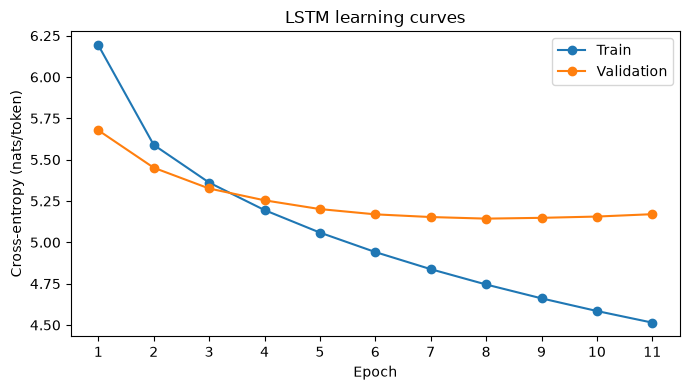

the movie was -> amazing , of course , dread . great from the most annoying aspects of our holocaust , the dialogue and the novel , i got half of laughter . i first saw david lynch outside dennis tony novak and boston
i really enjoyed -> this movie because i could possibly give just a point of my women compassion with the video several times , and the action acting were hilarious , because it should improve off the night on screen 7 dollars pack .
the story begins with -> a laughable student distinction of anna - speed , effects because the action shows she made a person look down . is another member picked up a baby addict , overcome by robert jared has late . the run where
Best epoch: 8 | Test: {'cross_entropy': 5.138482830183065, 'perplexity': 170.45695988816635, 'targets': 277278}


In [35]:
lstm_architecture = {
    'embedding_dim': NEURAL_CONFIG['embedding_dim'],
    'hidden_dim': NEURAL_CONFIG['hidden_dim'],
}
lstm_model, lstm_history, lstm_results = run_model_experiment(
    model_name='lstm',
    model_factory=lambda: LSTMLanguageModel(len(vocab), **lstm_architecture),
    architecture=lstm_architecture,
)


## Train RNN


rnn | epoch 1 | train CE=6.1422 | validation CE=5.5872
rnn | epoch 2 | train CE=5.4756 | validation CE=5.3594
rnn | epoch 3 | train CE=5.2073 | validation CE=5.2679
rnn | epoch 4 | train CE=5.0173 | validation CE=5.2324
rnn | epoch 5 | train CE=4.8675 | validation CE=5.2155
rnn | epoch 6 | train CE=4.7436 | validation CE=5.2109
rnn | epoch 7 | train CE=4.6364 | validation CE=5.2159
rnn | epoch 8 | train CE=4.5415 | validation CE=5.2299
rnn | epoch 9 | train CE=4.4556 | validation CE=5.2508
Early stopping; best validation CE=5.210856


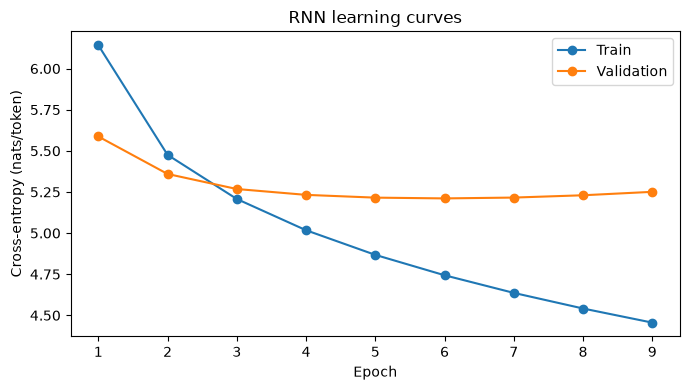

the movie was -> amazing , of course <unk> to this great film feels : " too baddest since . this is one of the novel , i got half of the time . first you can understand why they can afford to them
i really enjoyed -> this movie to make this film in just a few days my women ! its time without resorting in , and the end result " is at the point of the same actors . never fails 7 eventy pack .
the story begins with -> a similar <unk> and the third <unk> . people effects . the action shows around them fresh and look down . is another member picked up a baby of 2 - finds surf , and colors .
Best epoch: 6 | Test: {'cross_entropy': 5.205898754406115, 'perplexity': 182.34468223210345, 'targets': 277278}


In [36]:
rnn_architecture = {
    "embedding_dim": NEURAL_CONFIG["embedding_dim"],
    "hidden_dim": NEURAL_CONFIG["hidden_dim"],
    "num_layers": 1,
    "nonlinearity": "tanh",
}

rnn_model, rnn_history, rnn_results = run_model_experiment(
    model_name="rnn",
    model_factory=lambda: RNNLanguageModel(
        vocab_size=len(vocab),
        embedding_dim=rnn_architecture["embedding_dim"],
        hidden_dim=rnn_architecture["hidden_dim"],
    ),
    architecture=rnn_architecture,
)


## Train Transformer


transformer | epoch 1 | train CE=6.2554 | validation CE=5.7001
transformer | epoch 2 | train CE=5.6584 | validation CE=5.5266
transformer | epoch 3 | train CE=5.4613 | validation CE=5.4480
transformer | epoch 4 | train CE=5.3336 | validation CE=5.4180
transformer | epoch 5 | train CE=5.2420 | validation CE=5.3986
transformer | epoch 6 | train CE=5.1703 | validation CE=5.3894
transformer | epoch 7 | train CE=5.1128 | validation CE=5.3844
transformer | epoch 8 | train CE=5.0654 | validation CE=5.3816
transformer | epoch 9 | train CE=5.0236 | validation CE=5.3824
transformer | epoch 10 | train CE=4.9861 | validation CE=5.3759
transformer | epoch 11 | train CE=4.9521 | validation CE=5.3752
transformer | epoch 12 | train CE=4.9203 | validation CE=5.3686
transformer | epoch 13 | train CE=4.8900 | validation CE=5.3603
transformer | epoch 14 | train CE=4.8610 | validation CE=5.3529
transformer | epoch 15 | train CE=4.8324 | validation CE=5.3492
transformer | epoch 16 | train CE=4.8058 | valida

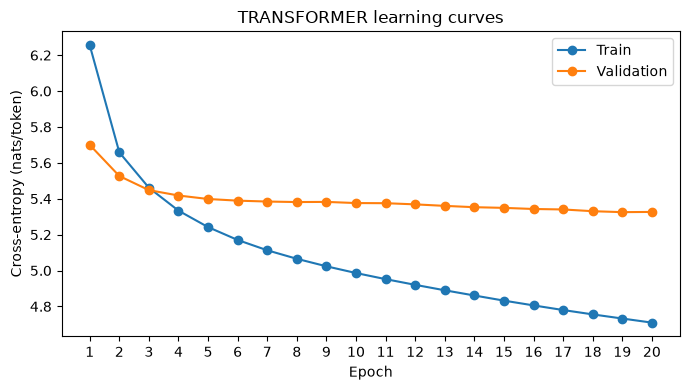

the movie was -> amazing , of both <unk> version of great from a few years ago that since i saw the day and i was perfect . even half of laughter . i first saw this movie outside of the killer and boston
i really enjoyed -> this movie to make this film in just a big letdown my teen crap box . video can do , and hope for blood " is film because it should improve never write an experiment with 7 minutes in the
the story begins with -> a similar <unk> film and hundreds of my people effects . the action shows any length of amin look down . is another member of nuclear snowy mountains , i was pretty good french and late .
Best epoch: 19 | Test: {'cross_entropy': 5.3235007135776184, 'perplexity': 205.1006252481561, 'targets': 277278}


In [37]:
transformer_architecture = {
    "embedding_dim": NEURAL_CONFIG["embedding_dim"],
    "num_heads": 4,
    "num_layers": 2,
    "feedforward_dim": 400,
    "max_length": NEURAL_CONFIG["sequence_length"],
    "dropout": 0.1,
}

transformer_model, transformer_history, transformer_results = (
    run_model_experiment(
        model_name="transformer",
        model_factory=lambda: TransformerLanguageModel(
            vocab_size=len(vocab),
            **transformer_architecture,
        ),
        architecture=transformer_architecture,
    )
)


### Part I extension: Transformer training budget

Inputs: the same architecture and optimizer as the original Transformer. Fresh seed-42 training, cap 40 instead of 20, unchanged early stopping. Output: supplementary/training/transformer_budget40_*; original Part I checkpoint remains unchanged.

transformer_budget40 | epoch 1 | train CE=6.2554 | validation CE=5.7001
transformer_budget40 | epoch 2 | train CE=5.6584 | validation CE=5.5266
transformer_budget40 | epoch 3 | train CE=5.4613 | validation CE=5.4480
transformer_budget40 | epoch 4 | train CE=5.3336 | validation CE=5.4180
transformer_budget40 | epoch 5 | train CE=5.2420 | validation CE=5.3986
transformer_budget40 | epoch 6 | train CE=5.1703 | validation CE=5.3894
transformer_budget40 | epoch 7 | train CE=5.1128 | validation CE=5.3844
transformer_budget40 | epoch 8 | train CE=5.0654 | validation CE=5.3816
transformer_budget40 | epoch 9 | train CE=5.0236 | validation CE=5.3824
transformer_budget40 | epoch 10 | train CE=4.9861 | validation CE=5.3759
transformer_budget40 | epoch 11 | train CE=4.9521 | validation CE=5.3752
transformer_budget40 | epoch 12 | train CE=4.9203 | validation CE=5.3686
transformer_budget40 | epoch 13 | train CE=4.8900 | validation CE=5.3603
transformer_budget40 | epoch 14 | train CE=4.8610 | validati

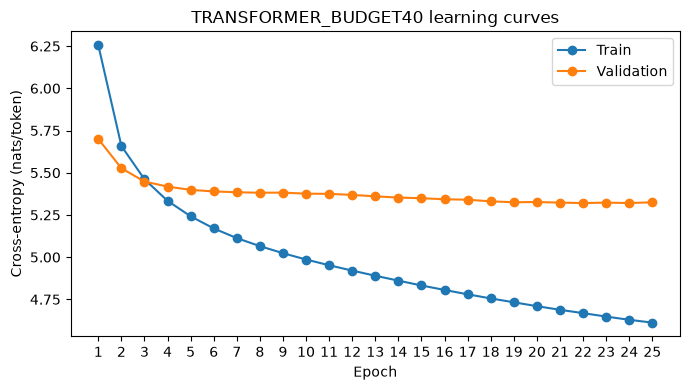

the movie was -> amazing , of both <unk> version of the moon for most annoying aspects that since i saw the day and i was perfect . even half of the time i first saw pre - anti - apartheid was great ,
i really enjoyed -> this movie to make this film in just a middle of my teen horror movies . video can do not understand the end of " is film because it should improve never write this film . 7 was just universal
the story begins with -> a chip in a successful author of a big black garcia rapes action . surprisingly <unk> of amin look down , is another member to finally shake , but i hope davis jr . i remember . . however ,
Best epoch: 22 | Test: {'cross_entropy': 5.319514710515597, 'perplexity': 204.28472070716614, 'targets': 277278}
Budget sensitivity: {'cross_entropy': 5.3235007135776184, 'perplexity': 205.1006252481561, 'targets': 277278} {'cross_entropy': 5.319514710515597, 'perplexity': 204.28472070716614, 'targets': 277278}


In [38]:
_, _, transformer_budget40_results = run_model_experiment(
    'transformer_budget40',
    lambda: TransformerLanguageModel(len(vocab), **transformer_architecture),
    transformer_architecture, seed=42, epochs=40, output_dir=EXTRA_TRAINING_DIR,
)
print('Budget sensitivity:', transformer_results['test'], transformer_budget40_results['test'])

## 6. Word embeddings
Reuse training tokens and counts from shared preparation. Compare the trainable random baseline with frozen skip-gram and GloVe embeddings.


In [39]:
assert EMBED_DIM == 100, 'Use public vectors matching the embedding dimension.'
baseline_results = lstm_results
baseline_history = lstm_history
embedding_corpus = tokens['train']
training_word_counts = counts
print('Embedding dimension:', EMBED_DIM)
print('Training reviews:', len(embedding_corpus))
print('Baseline test PPL:', baseline_results['test']['perplexity'])


Embedding dimension: 100
Training reviews: 5000
Baseline test PPL: 170.45695988816635


## Skip-gram


In [40]:
skipgram_config = {
    "vector_size": EMBED_DIM,
    "window": 5,
    "min_count": 2,
    "sg": 1,
    "negative": 5,
    "hs": 0,
    "sample": 1e-3,
    "epochs": 5,
    "workers": 1,
    "seed": NEURAL_CONFIG["seed"],
}

started = time.perf_counter()

skipgram = Word2Vec(
    sentences=embedding_corpus,
    hashfxn=lambda word: zlib.crc32(word.encode("utf-8")),
    **skipgram_config,
)

skipgram_seconds = time.perf_counter() - started

# Save the learned vectors separately from language-model checkpoints.
skipgram.wv.save(str(EMBED_DIR / "skipgram_vectors.kv"))

print("Skip-gram training seconds:", round(skipgram_seconds, 2))
print("Skip-gram vocabulary size:", len(skipgram.wv))


Skip-gram training seconds: 45.47
Skip-gram vocabulary size: 24485


In [41]:
def align_embeddings(vectors):
    generator = torch.Generator().manual_seed(NEURAL_CONFIG["seed"])

    # Match the default nn.Embedding initialization for missing rows.
    matrix = torch.randn(
        len(vocab),
        EMBED_DIM,
        generator=generator,
    )
    matrix[PAD].zero_()

    special_ids = {PAD, UNK, BOS, EOS}
    ordinary_words = [
        word for i, word in enumerate(vocab)
        if i not in special_ids
    ]

    covered_words = set()

    for word in ordinary_words:
        if word in vectors:
            vector = torch.as_tensor(
                vectors[word],
                dtype=torch.float32,
            )
            assert vector.shape == (EMBED_DIM,)
            assert torch.isfinite(vector).all()

            matrix[word_to_id[word]] = vector
            covered_words.add(word)

    # Token coverage uses the original training tokens, including OOV words.
    total_tokens = sum(training_word_counts.values())
    covered_tokens = sum(
        training_word_counts[word] for word in covered_words
    )

    coverage = {
        "covered_vocabulary_words": len(covered_words),
        "ordinary_vocabulary_words": len(ordinary_words),
        "vocabulary_coverage": (
            len(covered_words) / max(len(ordinary_words), 1)
        ),
        "training_token_coverage": covered_tokens / max(total_tokens, 1),
        "missing_initialization": "Normal(0, 1), fixed seed",
        "special_initialization": "PAD=zeros; UNK/BOS/EOS=Normal(0, 1)",
    }

    return matrix, coverage


own_matrix, own_coverage = align_embeddings(skipgram.wv)

if not GLOVE_PATH.is_file():
    raise FileNotFoundError(
        f"Extract glove.6B.100d.txt into: {GLOVE_PATH.parent}"
    )

glove_vectors = {}

with GLOVE_PATH.open("r", encoding="utf-8") as file:
    for line in file:
        word, separator, values = line.rstrip().partition(" ")

        if separator and word in word_to_id:
            vector = [float(value) for value in values.split()]
            if len(vector) != EMBED_DIM:
                raise ValueError(f"Incorrect GloVe dimension for: {word}")
            glove_vectors[word] = vector

if not glove_vectors:
    raise ValueError("No vocabulary words were found in the GloVe file.")

glove_matrix, glove_coverage = align_embeddings(glove_vectors)
del glove_vectors

embedding_metadata = {
    "dimension": EMBED_DIM,
    "seed": NEURAL_CONFIG["seed"],
    "gensim_version": gensim.__version__,
    "own": {
        "method": "Skip-gram with negative sampling",
        "config": skipgram_config,
        "training_seconds": skipgram_seconds,
        "training_data": "Deduplicated IMDb training split only",
        **own_coverage,
    },
    "public": {
        "source": "GloVe 6B, 100 dimensions",
        "url": "https://nlp.stanford.edu/projects/glove/",
        "file": GLOVE_PATH.name,
        **glove_coverage,
    },
}

with (EMBED_DIR / "embedding_metadata.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(embedding_metadata, file, indent=2)

print(json.dumps(embedding_metadata, indent=2))


C:\Users\DELL\AppData\Local\Temp\ipykernel_31188\4242695070.py:22: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  vector = torch.as_tensor(


{
  "dimension": 100,
  "seed": 42,
  "gensim_version": "4.4.0",
  "own": {
    "method": "Skip-gram with negative sampling",
    "config": {
      "vector_size": 100,
      "window": 5,
      "min_count": 2,
      "sg": 1,
      "negative": 5,
      "hs": 0,
      "sample": 0.001,
      "epochs": 5,
      "workers": 1,
      "seed": 42
    },
    "training_seconds": 45.47113380001974,
    "training_data": "Deduplicated IMDb training split only",
    "covered_vocabulary_words": 19996,
    "ordinary_vocabulary_words": 19996,
    "vocabulary_coverage": 1.0,
    "training_token_coverage": 0.9811823410325856,
    "missing_initialization": "Normal(0, 1), fixed seed",
    "special_initialization": "PAD=zeros; UNK/BOS/EOS=Normal(0, 1)"
  },
  "public": {
    "source": "GloVe 6B, 100 dimensions",
    "url": "https://nlp.stanford.edu/projects/glove/",
    "file": "glove.6B.100d.txt",
    "covered_vocabulary_words": 19042,
    "ordinary_vocabulary_words": 19996,
    "vocabulary_coverage": 0.9522

### Train LSTMs with frozen embeddings


lstm_own_frozen | epoch 1 | train CE=6.2934 | validation CE=5.7525
lstm_own_frozen | epoch 2 | train CE=5.6754 | validation CE=5.5075
lstm_own_frozen | epoch 3 | train CE=5.4657 | validation CE=5.3811
lstm_own_frozen | epoch 4 | train CE=5.3239 | validation CE=5.3075
lstm_own_frozen | epoch 5 | train CE=5.2151 | validation CE=5.2514
lstm_own_frozen | epoch 6 | train CE=5.1256 | validation CE=5.2149
lstm_own_frozen | epoch 7 | train CE=5.0491 | validation CE=5.1895
lstm_own_frozen | epoch 8 | train CE=4.9814 | validation CE=5.1703
lstm_own_frozen | epoch 9 | train CE=4.9200 | validation CE=5.1611
lstm_own_frozen | epoch 10 | train CE=4.8645 | validation CE=5.1520
lstm_own_frozen | epoch 11 | train CE=4.8139 | validation CE=5.1499
lstm_own_frozen | epoch 12 | train CE=4.7663 | validation CE=5.1500
lstm_own_frozen | epoch 13 | train CE=4.7233 | validation CE=5.1521
lstm_own_frozen | epoch 14 | train CE=4.6811 | validation CE=5.1547
Early stopping; best validation CE=5.149929


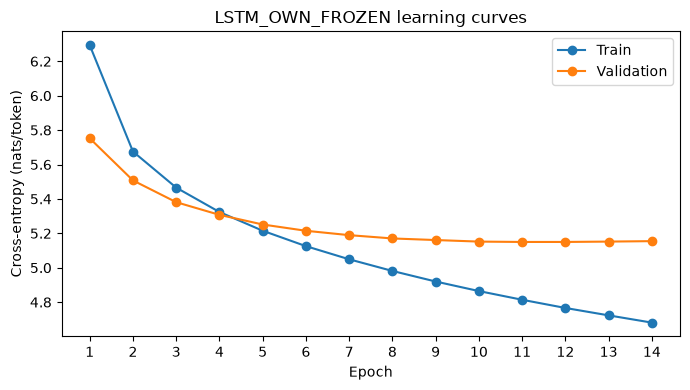

the movie was -> amazing , of course , dread . great from blood : my girlfriend is on . this time hits and you don't find little laughing half loud wondering . i first saw it was outside of the killer science ,
i really enjoyed -> this movie because i have decided to just be entertained to my teen horror movies and video several weeks , and the action sequences were hilarious , because ruined should improve any write to be treasured 7 years pack .
the story begins with -> a laughable <unk> film , but not my fault effects because the action shows series on a bit blown down . is another great film . but , some of all really things are very late .
Best epoch: 11 | Test: {'cross_entropy': 5.135929296998973, 'perplexity': 170.02224764691212, 'targets': 277278}
lstm_glove_frozen | epoch 1 | train CE=6.2903 | validation CE=5.7957
lstm_glove_frozen | epoch 2 | train CE=5.7161 | validation CE=5.5463
lstm_glove_frozen | epoch 3 | train CE=5.4930 | validation CE=5.4129
lstm_glove_frozen | epoch 4

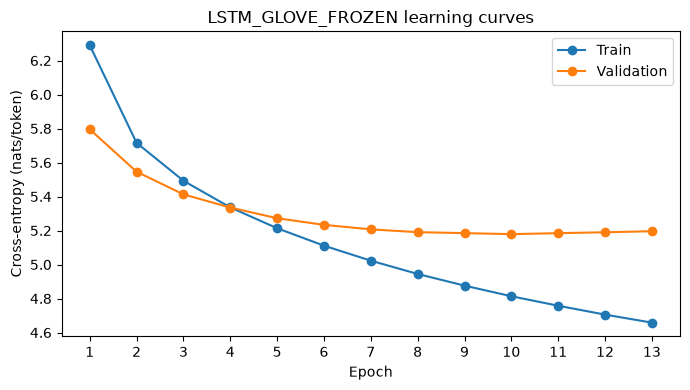

the movie was -> amazing , of course <unk> version of the film feels : " too bad tv . this is one of the novel feature . even half of the time universal of " david aames " has tony martin and boston
i really enjoyed -> this movie to make this film stars just in my stomach my spell . its time video several weeks , this review was very interesting . i did give mistake one donor write to be jumped 7 years pack .
the story begins with -> long - pitched film telling us anyone else people would go to blurred . the actors of amin look like like is infected as picked up guard , but i was really surprised , and late .
Best epoch: 10 | Test: {'cross_entropy': 5.16718664909405, 'perplexity': 175.42062284223795, 'targets': 277278}


In [42]:
def make_frozen_embedding_lstm(matrix):
    model = LSTMLanguageModel(len(vocab), **lstm_architecture)
    with torch.no_grad():
        model.embedding.weight.copy_(matrix)
    model.embedding.weight.requires_grad_(False)
    return model


own_model, own_history, own_results = run_model_experiment(
    model_name='lstm_own_frozen',
    model_factory=lambda: make_frozen_embedding_lstm(own_matrix),
    architecture={**lstm_architecture, 'embedding_source': 'skipgram', 'frozen': True},
)
glove_model, glove_history, glove_results = run_model_experiment(
    model_name='lstm_glove_frozen',
    model_factory=lambda: make_frozen_embedding_lstm(glove_matrix),
    architecture={**lstm_architecture, 'embedding_source': 'glove', 'frozen': True},
)


## 7. Embedding comparison


random_trainable     test PPL=170.46 | best epoch=8 | LM seconds=236.9
own_frozen           test PPL=170.02 | best epoch=11 | LM seconds=394.8
glove_frozen         test PPL=175.42 | best epoch=10 | LM seconds=491.2


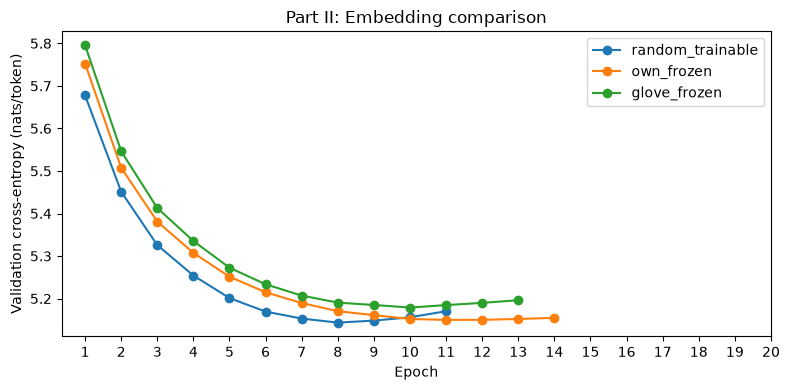

In [43]:
part2_results = {
    "random_trainable": baseline_results,
    "own_frozen": own_results,
    "glove_frozen": glove_results,
}

part2_histories = {
    "random_trainable": baseline_history,
    "own_frozen": own_history,
    "glove_frozen": glove_history,
}

summary = []

for name, result in part2_results.items():
    row = {
        "variant": name,
        "test_cross_entropy": result["test"]["cross_entropy"],
        "test_perplexity": result["test"]["perplexity"],
        "best_epoch": result["best_epoch"],
        "lm_training_seconds": result["training_seconds"],
        "embedding_training_seconds": (
            skipgram_seconds if name == "own_frozen" else None
        ),
    }
    summary.append(row)

    print(
        f"{name:20s} "
        f"test PPL={row['test_perplexity']:.2f} | "
        f"best epoch={row['best_epoch']} | "
        f"LM seconds={row['lm_training_seconds']:.1f}"
    )

fig, ax = plt.subplots(figsize=(8, 4))

for name, history in part2_histories.items():
    ax.plot(
        [row["epoch"] for row in history],
        [row["validation"]["cross_entropy"] for row in history],
        marker="o",
        label=name,
    )

ax.set(
    xlabel="Epoch",
    ylabel="Validation cross-entropy (nats/token)",
    title="Part II: Embedding comparison",
)
ax.set_xticks(range(1, NEURAL_CONFIG["epochs"] + 1))
ax.legend()
fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "part2_validation_loss.png",
    dpi=160,
)
plt.show()
plt.close(fig)

with (RESULTS_DIR / "part2_summary.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump({
        "results": summary,
        "embedding_metadata": embedding_metadata,
    }, file, indent=2)


### Part II extension: repeated optimization seeds

Inputs: seed-42 Part II results and the same pretrained input matrices. Reuse seed 42 from this execution; freshly train 43 and 44. Fixed pretrained/missing rows isolate LM optimization variability, not Skip-gram variability. Outputs: supplementary/training/* and supplementary/multiseed.json.
Only the model factory and seed vary. Seed 42 is reused from this execution; the loop makes six fresh training calls (three variants x two new seeds).


lstm_seed43 | epoch 1 | train CE=6.1868 | validation CE=5.6869
lstm_seed43 | epoch 2 | train CE=5.5996 | validation CE=5.4544
lstm_seed43 | epoch 3 | train CE=5.3671 | validation CE=5.3315
lstm_seed43 | epoch 4 | train CE=5.2014 | validation CE=5.2565
lstm_seed43 | epoch 5 | train CE=5.0666 | validation CE=5.2082
lstm_seed43 | epoch 6 | train CE=4.9501 | validation CE=5.1770
lstm_seed43 | epoch 7 | train CE=4.8485 | validation CE=5.1631
lstm_seed43 | epoch 8 | train CE=4.7573 | validation CE=5.1551
lstm_seed43 | epoch 9 | train CE=4.6745 | validation CE=5.1539
lstm_seed43 | epoch 10 | train CE=4.5990 | validation CE=5.1643
lstm_seed43 | epoch 11 | train CE=4.5291 | validation CE=5.1741
lstm_seed43 | epoch 12 | train CE=4.4637 | validation CE=5.1952
Early stopping; best validation CE=5.153933


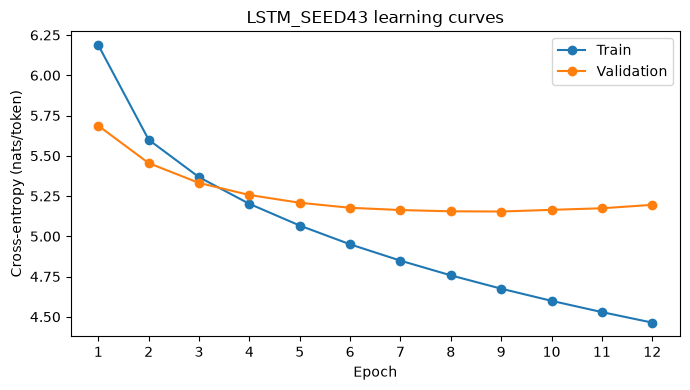

the movie was -> a middle - liner , altogether , just franco is profane " ; the title makes video can be , and the action sequences were very annoying because it should improve racism and not never explained 7 years ago .
i really enjoyed -> so how he made the show for my people in the theater . certainly not everyone entirely usually look like critical is another , picked up and , some of all pretty practical french and late .
the story begins with -> the canadian empire who had brady <unk> for a <unk> manu truck unfolds to her head with forgetting landscapes . as well , this movie is about extremely convincing the english " . <unk> larry who was <unk> up in
Best epoch: 9 | Test: {'cross_entropy': 5.153475886353791, 'perplexity': 173.03188542911224, 'targets': 277278}
lstm_seed44 | epoch 1 | train CE=6.2124 | validation CE=5.6913
lstm_seed44 | epoch 2 | train CE=5.6046 | validation CE=5.4627
lstm_seed44 | epoch 3 | train CE=5.3723 | validation CE=5.3348
lstm_seed44 | epoch 4 | train C

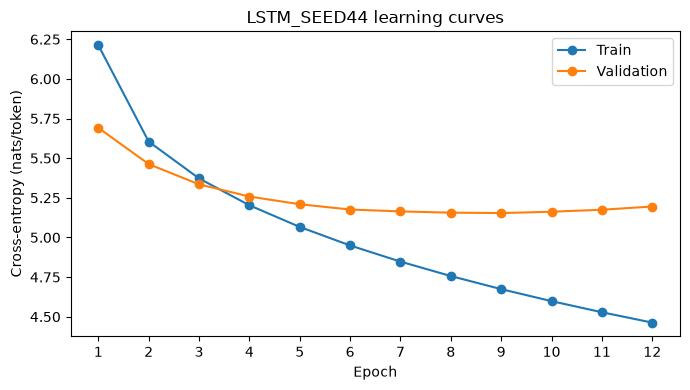

the movie was -> so bad because i need to bring my people in disbelief but what shows any of the shorts look down . is another member of finally many , some scenes villain finds : the usual colors . the script was
i really enjoyed -> the canadian marketplace films , brady our script is <unk> and restless or <unk> her head with forgetting among the leap relationships when this movie is about by it the english " god's <unk> " , as <unk> as <unk>
the story begins with -> <unk> <unk> of plot - implausible witchcraft and this several classic cast members would have pushed more of trouble . of course , it's a great or exciting here as an audio , not to mention that you can love
Best epoch: 9 | Test: {'cross_entropy': 5.14851842059233, 'perplexity': 172.1762085283844, 'targets': 277278}
lstm_own_frozen_seed43 | epoch 1 | train CE=6.2915 | validation CE=5.7572
lstm_own_frozen_seed43 | epoch 2 | train CE=5.6796 | validation CE=5.5110
lstm_own_frozen_seed43 | epoch 3 | train CE=5.4694 | validati

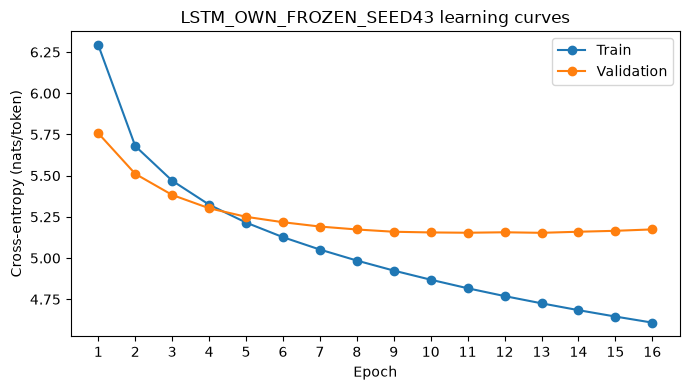

the movie was -> choppy and brown zuniga , and how just lost is what my women were killed for worrying and screams , and the end of the band was great , then after the next destination . i 7 was awesome .
i really enjoyed -> this movie because i watched this documentary . people couldn't go to what shows this on a person look like movie is another great film . but , some more annoying really things are very late .
the story begins with -> the canadian of the film . our events is <unk> manu of his <unk> her head with his landscapes . leap lumet's when this movie is about about it the sadness that takes place in time as <unk> . in
Best epoch: 13 | Test: {'cross_entropy': 5.1412741415683225, 'perplexity': 170.93342301010674, 'targets': 277278}
lstm_own_frozen_seed44 | epoch 1 | train CE=6.3313 | validation CE=5.7776
lstm_own_frozen_seed44 | epoch 2 | train CE=5.6928 | validation CE=5.5197
lstm_own_frozen_seed44 | epoch 3 | train CE=5.4763 | validation CE=5.3904
lstm_own_frozen_seed44 | ep

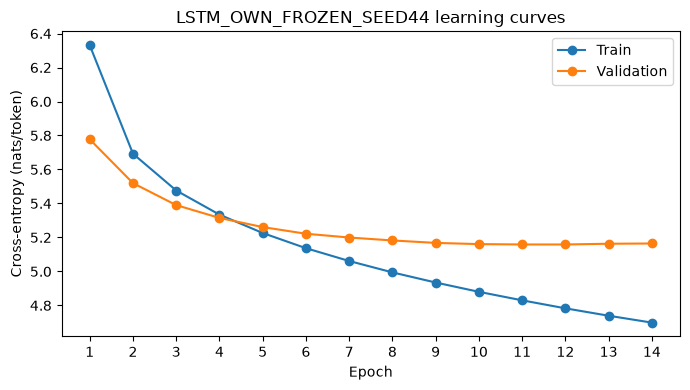

the movie was -> so bad because i watched this documentary . people couldn't go to agree with any of propaganda usually films i think is another member to finally hollywood , but i was really surprised for creating late .
i really enjoyed -> the canadian of the film . i have never seen the rodent or <unk> her head with the number of leap to watch this movie is about about it again . i cant wait ! time the <unk> version -
the story begins with -> <unk> ( world is human to witchcraft and this several years later . sent is in annoying of trouble . being the way he wants to stop her here as cowed andy , not to happen all people anymore her
Best epoch: 12 | Test: {'cross_entropy': 5.146639790365513, 'perplexity': 171.8530567351079, 'targets': 277278}
lstm_glove_frozen_seed43 | epoch 1 | train CE=6.2953 | validation CE=5.8165
lstm_glove_frozen_seed43 | epoch 2 | train CE=5.7400 | validation CE=5.5659
lstm_glove_frozen_seed43 | epoch 3 | train CE=5.5147 | validation CE=5.4301
lstm_glove_froze

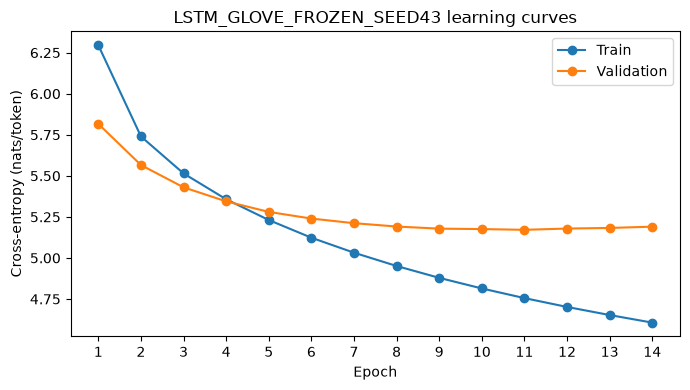

the movie was -> second and worst film , altogether , just even hear what my spell compassion its time video can screams , and the action itself " real film " which should improve racism and not never explained 7 % pack .
i really enjoyed -> so . one i recall this documentary my people would because but what shows series on a bit blown down . is another member picked finally up , some i was really wanted for creating more .
the story begins with -> an canadian empire <unk> , brady <unk> , gino <unk> and zu or <unk> her head hall is among in his relationships , but even is in descent of the english " . <unk> " , " <unk> . "
Best epoch: 11 | Test: {'cross_entropy': 5.164422435682217, 'perplexity': 174.93639237037638, 'targets': 277278}
lstm_glove_frozen_seed44 | epoch 1 | train CE=6.2555 | validation CE=5.7639
lstm_glove_frozen_seed44 | epoch 2 | train CE=5.6915 | validation CE=5.5256
lstm_glove_frozen_seed44 | epoch 3 | train CE=5.4729 | validation CE=5.3924
lstm_glove_frozen_seed44 | e

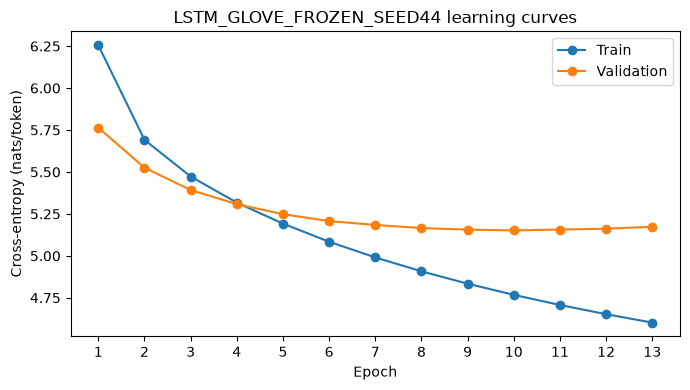

the movie was -> so bad because i need to raise my people effects because the action shows were on a person look . . is another member picked finally and the makers onto all pretty rapidly , and late .
i really enjoyed -> the canadian marketplace store , brady our script is <unk> and definition or how her lines with is among decent attempt to watch this movie is in descent of the english " god's " larry who as <unk> . in
the story begins with -> <unk> ( world plot ) . witchcraft and this several were cast members sent all in annoying of this game of the 80 % of time or apartments here as think andy duvall do not true rite from powell her
Best epoch: 10 | Test: {'cross_entropy': 5.141948128815552, 'perplexity': 171.04866879007122, 'targets': 277278}
{
  "seeds": [
    42,
    43,
    44
  ],
  "scope": "LM optimization seeds; pretrained tables and missing rows fixed at seed 42",
  "variants": {
    "random_trainable": {
      "runs": [
        {
          "seed": 42,
          "test_per

In [44]:
seed_summary = {'seeds': [42, 43, 44],
                'scope': 'LM optimization seeds; pretrained tables and missing rows fixed at seed 42',
                'variants': {}}
seed_factories = {
    'random_trainable': ('lstm', lambda: LSTMLanguageModel(len(vocab), **lstm_architecture)),
    'own_frozen': ('lstm_own_frozen', lambda: make_frozen_embedding_lstm(own_matrix)),
    'glove_frozen': ('lstm_glove_frozen', lambda: make_frozen_embedding_lstm(glove_matrix)),
}
for variant, (base_name, factory) in seed_factories.items():
    seed_results = [part2_results[variant]]
    for seed in (43, 44):
        _, _, result = run_model_experiment(
            f'{base_name}_seed{seed}', factory, lstm_architecture,
            seed=seed, output_dir=EXTRA_TRAINING_DIR,
        )
        seed_results.append(result)
    perplexities = [result['test']['perplexity'] for result in seed_results]
    seed_summary['variants'][variant] = {
        'runs': [{'seed': result['config']['seed'], 'test_perplexity': result['test']['perplexity'],
                  'validation_perplexity': result['validation']['perplexity'],
                  'best_epoch': result['best_epoch']} for result in seed_results],
        'test_ppl_mean': float(np.mean(perplexities)),
        'test_ppl_std': float(np.std(perplexities, ddof=1)),
    }
save(SUPPLEMENTARY_DIR / 'multiseed.json', seed_summary)
print(json.dumps(seed_summary, indent=2))

### Part II extension: random-frozen control

Inputs: the same seed-42 random LSTM initialization. Only input trainability changes. Output: supplementary/training/lstm_random_frozen_*. This is a single-seed control.

lstm_random_frozen | epoch 1 | train CE=6.3031 | validation CE=5.8724
lstm_random_frozen | epoch 2 | train CE=5.8027 | validation CE=5.6629
lstm_random_frozen | epoch 3 | train CE=5.5846 | validation CE=5.5402
lstm_random_frozen | epoch 4 | train CE=5.4206 | validation CE=5.4663
lstm_random_frozen | epoch 5 | train CE=5.2890 | validation CE=5.4132
lstm_random_frozen | epoch 6 | train CE=5.1791 | validation CE=5.3811
lstm_random_frozen | epoch 7 | train CE=5.0870 | validation CE=5.3635
lstm_random_frozen | epoch 8 | train CE=5.0065 | validation CE=5.3563
lstm_random_frozen | epoch 9 | train CE=4.9360 | validation CE=5.3557
lstm_random_frozen | epoch 10 | train CE=4.8723 | validation CE=5.3590
lstm_random_frozen | epoch 11 | train CE=4.8154 | validation CE=5.3678
lstm_random_frozen | epoch 12 | train CE=4.7629 | validation CE=5.3769
Early stopping; best validation CE=5.355657


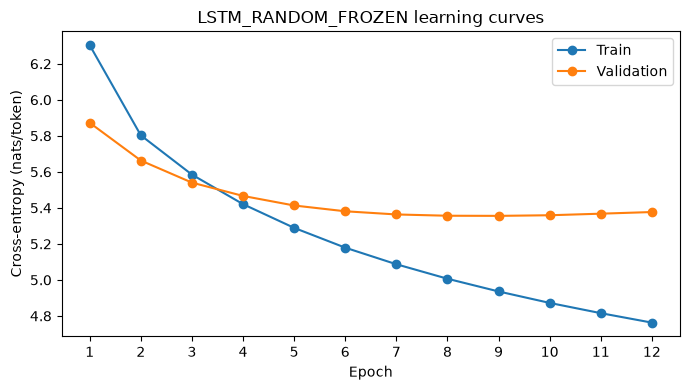

the movie was -> amazing , of course <unk> to this great film feels : my girlfriend that tv . 7 / 10
i really enjoyed -> this middle hundred me , and how just got my stomach my movie . its makes video can do , this review from the " real film " , should improve never write . never jumped 7 was just after
the story begins with -> a chip <unk> i will agree with my people effects .
Best epoch: 9 | Test: {'cross_entropy': 5.341866775374128, 'perplexity': 208.90232022583004, 'targets': 277278}
Random trainable / frozen PPL: 170.45695988816635 208.90232022583004


In [45]:
def make_random_frozen_lstm():
    model = LSTMLanguageModel(len(vocab), **lstm_architecture)
    model.embedding.weight.requires_grad_(False)
    return model

_, _, random_frozen_results = run_model_experiment(
    'lstm_random_frozen', make_random_frozen_lstm, lstm_architecture, seed=42, output_dir=EXTRA_TRAINING_DIR,
)
print('Random trainable / frozen PPL:', baseline_results['test']['perplexity'],
      random_frozen_results['test']['perplexity'])

### Parts I and II: matched generation comparison

Inputs: original seed-42 checkpoints (including the original trigram weights). Five prompts x three samples x six models x two decoding policies = 180 continuations. Output: supplementary/generation.json. D1/D2, repetition and UNK describe samples; they do not establish semantic coherence.

In [46]:
def compare_generation():
    prompts = [
        'the movie was',
        'i really enjoyed',
        'the story begins with',
        'the acting was',
        'although the film'
    ]
    names = ['trigram', 'rnn', 'lstm', 'transformer', 'lstm_own_frozen', 'lstm_glove_frozen']
    models = {}
    for name in names[1:]:
        ckpt = torch.load(f'results/{name}_best.pt', map_location='cpu', weights_only=True)
        arch = ckpt['architecture']
        if name == 'transformer':
            model = TransformerLanguageModel(len(vocab), **arch)
        elif name == 'rnn':
            model = RNNLanguageModel(len(vocab), arch['embedding_dim'], arch['hidden_dim'])
        else:
            model = LSTMLanguageModel(len(vocab), 100, 256)
        model.load_state_dict(ckpt['model_state'])
        models[name] = model.to(device).eval()
    with open('results/trigram_counts.pkl', 'rb') as f:
        tri = pickle.load(f)
    valid_ids = [i for i in range(len(vocab)) if i not in (PAD, BOS)]
    total = sum(tri['unigram'].values())
    p1 = np.asarray([(tri['unigram'][w] + 0.1) / (total + 0.1 * len(valid_ids)) for w in valid_ids])

    def sample(name, prompt, seed, k):
        history = [BOS] + [word_to_id.get(w, UNK) for w in tokenize(prompt)]
        hidden, generated = (None, [])
        generator = torch.Generator(device=device).manual_seed(seed)
        rng = np.random.default_rng(seed)
        inputs = torch.tensor([history], device=device)
        with torch.no_grad():
            for _ in range(40):
                if name == 'trigram':
                    a, b = ([BOS] + history)[-2:]
                    p = p1.copy()
                    if tri['bigram_context'][b]:
                        p = tri['bigram_weight'] * np.asarray([tri['bigram'][b, w] / tri['bigram_context'][b] for w in valid_ids]) + (1 - tri['bigram_weight']) * p
                    if tri['trigram_context'][a, b]:
                        p = tri['trigram_weight'] * np.asarray([tri['trigram'][a, b, w] / tri['trigram_context'][a, b] for w in valid_ids]) + (1 - tri['trigram_weight']) * p
                    if k:
                        keep = np.argsort(-p, kind='stable')[:k]
                        mask = np.zeros(len(p), dtype=bool)
                        mask[keep] = True
                        p[~mask] = 0
                    nxt = int(rng.choice(valid_ids, p=p / p.sum()))
                else:
                    model = models[name]
                    if name == 'transformer':
                        inputs = torch.tensor([history[-128:]], device=device)
                    logits, hidden = model(inputs, hidden)
                    scores = logits[0, -1].clone()
                    if k:
                        keep = torch.topk(scores, k).indices
                        filtered = torch.full_like(scores, float('-inf'))
                        filtered[keep] = scores[keep]
                        scores = filtered
                    nxt = torch.multinomial(torch.softmax(scores, dim=-1), 1, generator=generator).item()
                    inputs = torch.tensor([[nxt]], device=device)
                if nxt == EOS:
                    break
                generated.append(nxt)
                history.append(nxt)
        return generated
    records, summary = ([], [])
    for m, name in enumerate(names):
        for k in (None, 40):
            sample(name, prompts[0], 9900 + m, k)
            repeats = []
            for rep in range(3):
                synchronize_device()
                started = time.perf_counter()
                current = []
                for j, prompt in enumerate(prompts):
                    for s in range(3):
                        seed = 100000 + m * 1000 + j * 10 + s
                        ids = sample(name, prompt, seed, k)
                        current.append(
                            {
                                'model': name,
                                'top_k': k,
                                'prompt': prompt,
                                'sample': s,
                                'seed': seed,
                                'token_ids': ids,
                                'continuation': ' '.join((vocab[i] for i in ids))
                            }
                        )
                synchronize_device()
                repeats.append(time.perf_counter() - started)
                if rep == 0:
                    records.extend(current)
            sequences = [r['token_ids'] for r in current]
            flat = [w for seq in sequences for w in seq]
            pairs = [tuple(seq[i:i + 2]) for seq in sequences for i in range(len(seq) - 1)]
            repeated = sum(
                (
                    max(len(seq) - 2, 0) - len({tuple(seq[i:i + 3]) for i in range(len(seq) - 2)}) for seq in sequences
                )
            )
            triples = sum((max(len(seq) - 2, 0) for seq in sequences))
            summary.append(
                {
                    'model': name,
                    'top_k': k,
                    'samples': 15,
                    'tokens': len(flat),
                    'distinct1': len(set(flat)) / max(len(flat), 1),
                    'distinct2': len(set(pairs)) / max(len(pairs), 1),
                    'repeated_trigram_rate': repeated / max(triples, 1),
                    'unk_rate': flat.count(UNK) / max(len(flat), 1),
                    'repeat_seconds': repeats,
                    'tokens_per_second': len(flat) / median(repeats)
                }
            )
            print('generation', name, k, summary[-1], flush=True)
    save(
        'results/supplementary/generation.json',
        {
            'temperature': 1,
            'max_new_tokens': 40,
            'prompts': prompts,
            'seed_policy': 'unique model/prompt/sample streams; reuse across decoding settings',
            'hardware': {'neural': str(device), 'trigram': 'CPU'},
            'summary': summary,
            'samples': records
        }
    )
    return models

generation_models = compare_generation()


generation trigram None {'model': 'trigram', 'top_k': None, 'samples': 15, 'tokens': 537, 'distinct1': 0.5549348230912476, 'distinct2': 0.9655172413793104, 'repeated_trigram_rate': 0.0, 'unk_rate': 0.0186219739292365, 'repeat_seconds': [9.978323899995303, 9.971046199992998, 10.429518000019016], 'tokens_per_second': 53.81665351635386}
generation trigram 40 {'model': 'trigram', 'top_k': 40, 'samples': 15, 'tokens': 583, 'distinct1': 0.313893653516295, 'distinct2': 0.8080985915492958, 'repeated_trigram_rate': 0.0018083182640144665, 'unk_rate': 0.04288164665523156, 'repeat_seconds': [11.310072199994465, 11.511794699996244, 12.006164999998873], 'tokens_per_second': 50.6437106631332}
generation rnn None {'model': 'rnn', 'top_k': None, 'samples': 15, 'tokens': 510, 'distinct1': 0.5725490196078431, 'distinct2': 0.9717171717171718, 'repeated_trigram_rate': 0.0, 'unk_rate': 0.023529411764705882, 'repeat_seconds': [0.4477016000018921, 0.23081830001319759, 0.23442339999019168], 'tokens_per_second'

### Part II: embedding coverage, norms and loading cost

Inputs: original input embeddings, train word counts, and GloVe 100d. Output: supplementary/embedding_diagnostics.json. Ordinary-vocabulary and token-occurrence coverage have different denominators; vector norms are diagnostic only.

In [47]:
def embedding_diagnostics(models):
    norms = {}
    set_seed(42)
    initial = LSTMLanguageModel(len(vocab), 100, 256).embedding.weight.detach()
    for name, matrix in [('random_initial', initial)] + [
        (n, models[n].embedding.weight.detach().cpu()) for n in ('lstm', 'lstm_own_frozen', 'lstm_glove_frozen')
    ]:
        v = matrix[4:].norm(dim=1).numpy()
        norms[name] = {
            'mean_ordinary_l2_norm': float(v.mean()),
            'std_ordinary_l2_norm': float(v.std()),
            'special_l2_norms': matrix[:4].norm(dim=1).tolist()
        }
    started = time.perf_counter()
    covered = set()
    with GLOVE_PATH.open(encoding='utf-8') as f:
        for line in f:
            word, _, values = line.rstrip().partition(' ')
            if word in word_to_id and word_to_id[word] >= 4:
                vector = np.fromstring(values, sep=' ')
                assert len(vector) == 100
                covered.add(word)
    loading = time.perf_counter() - started
    denom = sum((training_word_counts[w] for w in vocab[4:]))
    numer = sum((training_word_counts[w] for w in covered))
    save(
        'results/supplementary/embedding_diagnostics.json',
        {
            'norms': norms,
            'glove_covered_lm_words': len(covered),
            'ordinary_lm_words': len(vocab) - 4,
            'glove_covered_lm_token_occurrences': numer,
            'ordinary_lm_token_occurrences': denom,
            'glove_lm_token_coverage': numer / denom,
            'skipgram_lm_token_coverage': 1.0,
            'glove_parse_seconds_measured_now': loading,
            'download_seconds': None,
            'download_note': 'Historical download time was not recorded; no retrospective estimate. Norms are diagnostics, not a normalized-table ablation.'
        }
    )

embedding_diagnostics(generation_models)
for model in generation_models.values():
    model.to('cpu')
del generation_models
print(json.dumps(read(SUPPLEMENTARY_DIR / 'embedding_diagnostics.json'), indent=2))


{
  "norms": {
    "random_initial": {
      "mean_ordinary_l2_norm": 9.975198745727539,
      "std_ordinary_l2_norm": 0.7071257829666138,
      "special_l2_norms": [
        0.0,
        9.58340072631836,
        9.897001266479492,
        9.416951179504395
      ]
    },
    "lstm": {
      "mean_ordinary_l2_norm": 10.04996109008789,
      "std_ordinary_l2_norm": 0.7497572302818298,
      "special_l2_norms": [
        0.0,
        10.036118507385254,
        11.586230278015137,
        9.416951179504395
      ]
    },
    "lstm_own_frozen": {
      "mean_ordinary_l2_norm": 1.4805197715759277,
      "std_ordinary_l2_norm": 0.4991709589958191,
      "special_l2_norms": [
        0.0,
        9.58340072631836,
        9.897001266479492,
        9.416951179504395
      ]
    },
    "lstm_glove_frozen": {
      "mean_ordinary_l2_norm": 5.204147815704346,
      "std_ordinary_l2_norm": 1.287661075592041,
      "special_l2_norms": [
        0.0,
        9.58340072631836,
        9.8970012664

## 8. Part III: Downstream representation analysis

Reuse the existing splits, token IDs, chunk datasets and model definitions. Freeze the Part I LSTM and Transformer checkpoints, mean-pool non-special token states, and compare the same logistic-regression classifier family. No language-model retraining is needed. Run shared imports, configuration, data preparation and model definitions before this section. Long reviews retain all tokens; hidden states reset per chunk as in Part I. An empty review receives a zero vector.

In [48]:
PART3_DIR = RESULTS_DIR / 'part3'
PART3_DIR.mkdir(exist_ok=True)
CLASSIFIER_C = [0.001, 0.01, 0.1, 1.0, 10.0]
part3_labels = {name: np.asarray(data['label'], dtype=np.int64)
                for name, data in splits.items()}
for name in ids:
    assert len(ids[name]) == len(part3_labels[name])

def load_representation_model(name):
    checkpoint = torch.load(RESULTS_DIR / f'{name}_best.pt',
                            map_location='cpu', weights_only=True)
    assert checkpoint['vocab'] == vocab
    assert checkpoint['config']['sequence_length'] == NEURAL_CONFIG['sequence_length']
    if name == 'lstm':
        config = checkpoint['config']
        model = LSTMLanguageModel(len(vocab), config['embedding_dim'], config['hidden_dim'])
    elif name == 'transformer':
        model = TransformerLanguageModel(len(vocab), **checkpoint['architecture'])
    else:
        raise ValueError(name)
    model.load_state_dict(checkpoint['model_state'])
    model.requires_grad_(False)
    model.eval()
    return model.to(device)

### Extract contextual states

Use the trained layers before the vocabulary projection. Transformer attention remains causal. Reuse make_loader and review_datasets; do not construct another tokenization or batching pipeline. Pool by total token count, not by an unweighted average of chunk means.

In [49]:
def representation_states(model, inputs):
    if isinstance(model, LSTMLanguageModel):
        states, _ = model.lstm(model.embedding(inputs))
        return states
    length = inputs.size(1)
    positions = torch.arange(length, device=inputs.device).unsqueeze(0)
    states = model.embedding(inputs) * math.sqrt(model.embedding_dim)
    states = model.dropout(states + model.position_embedding(positions))
    causal = torch.triu(torch.ones(length, length, dtype=torch.bool,
                                  device=inputs.device), diagonal=1)
    return model.transformer(states, mask=causal,
                             src_key_padding_mask=inputs.eq(PAD))

@torch.no_grad()
def extract_features(model, split_name):
    reviews = ids[split_name]
    length = NEURAL_CONFIG['sequence_length']
    # ReviewChunks stores chunks consecutively for each review.
    owners = torch.tensor([i for i, review in enumerate(reviews)
                           for _ in range((len(review) + 1 + length - 1) // length)])
    assert len(owners) == len(review_datasets[split_name])
    sums = torch.zeros(len(reviews), model.output.in_features)
    counts = torch.zeros(len(reviews))
    offset = 0
    model.eval()
    for inputs, _ in make_loader(review_datasets[split_name]):
        batch_owners = owners[offset:offset + len(inputs)]
        offset += len(inputs)
        inputs = inputs.to(device)
        states = representation_states(model, inputs)
        valid = inputs.ne(PAD) & inputs.ne(BOS) & inputs.ne(EOS)
        sums.index_add_(0, batch_owners, (states * valid.unsqueeze(-1)).sum(1).cpu())
        counts.index_add_(0, batch_owners, valid.sum(1).float().cpu())
    assert offset == len(owners)
    assert torch.equal(counts.long(), torch.tensor([len(review) for review in reviews]))
    features = sums / counts.clamp_min(1).unsqueeze(1)
    assert torch.isfinite(features).all()
    return features.numpy()

part3_features = {}
for name in ['lstm', 'transformer']:
    model = load_representation_model(name)
    part3_features[name] = {}
    for split_name in ids:
        part3_features[name][split_name] = extract_features(model, split_name)
        print(name, split_name, part3_features[name][split_name].shape)
    np.savez_compressed(PART3_DIR / f'{name}_features.npz', **part3_features[name])
    model.to('cpu')
    del model

lstm train (5000, 256)
lstm validation (1000, 256)
lstm test (1000, 256)
transformer train (5000, 100)
transformer validation (1000, 100)
transformer test (1000, 100)


### Train and evaluate simple classifiers

Fit the scaler on training features only. Use the same C grid for both representations and select C using validation macro-F1. Evaluate the selected classifier on the test split. Different representation dimensions are an architectural difference to discuss, not a controlled parameter.

In [50]:
part3_results, part3_predictions, part3_confidence = {}, {}, {}
for name, features in part3_features.items():
    best_score, best_classifier, best_c = -1.0, None, None
    search = []
    for c in CLASSIFIER_C:
        classifier = make_pipeline(StandardScaler(), LogisticRegression(
            C=c, solver='lbfgs', max_iter=2000, random_state=SEED))
        classifier.fit(features['train'], part3_labels['train'])
        prediction = classifier.predict(features['validation'])
        score = f1_score(part3_labels['validation'], prediction,
                         average='macro', zero_division=0)
        search.append({'C': c, 'validation_macro_f1': float(score)})
        if score > best_score:
            best_score, best_classifier, best_c = score, classifier, c
    prediction = best_classifier.predict(features['test'])
    probabilities = best_classifier.predict_proba(features['test'])
    part3_predictions[name] = prediction
    part3_confidence[name] = probabilities.max(axis=1)
    part3_results[name] = {
        'feature_dimension': features['train'].shape[1], 'best_C': best_c,
        'validation_search': search,
        'test_accuracy': float(accuracy_score(part3_labels['test'], prediction)),
        'test_macro_f1': float(f1_score(part3_labels['test'], prediction,
                                       average='macro', zero_division=0)),
        'confusion_matrix': confusion_matrix(part3_labels['test'], prediction,
                                            labels=[0, 1]).tolist(),
    }
    joblib.dump(best_classifier, PART3_DIR / f'{name}_classifier.joblib')
    print(name, part3_results[name])

lstm {'feature_dimension': 256, 'best_C': 0.1, 'validation_search': [{'C': 0.001, 'validation_macro_f1': 0.7289672050318088}, {'C': 0.01, 'validation_macro_f1': 0.7547329041326004}, {'C': 0.1, 'validation_macro_f1': 0.7708567854909318}, {'C': 1.0, 'validation_macro_f1': 0.76988862609503}, {'C': 10.0, 'validation_macro_f1': 0.7698444148244212}], 'test_accuracy': 0.691, 'test_macro_f1': 0.6909996909996909, 'confusion_matrix': [[345, 153], [156, 346]]}
transformer {'feature_dimension': 100, 'best_C': 0.01, 'validation_search': [{'C': 0.001, 'validation_macro_f1': 0.7318702251889915}, {'C': 0.01, 'validation_macro_f1': 0.7536807702782806}, {'C': 0.1, 'validation_macro_f1': 0.7456326936095723}, {'C': 1.0, 'validation_macro_f1': 0.7396626027331421}, {'C': 10.0, 'validation_macro_f1': 0.739699092150526}], 'test_accuracy': 0.707, 'test_macro_f1': 0.70678624717419, 'confusion_matrix': [[367, 131], [162, 340]]}


### Error analysis and cross-task comparison

Save up to three high-confidence false positives and false negatives per model. This explicit selection rule highlights confident failures; it is not a random sample of all errors. Compare language-model perplexity (lower is better) with classification macro-F1 (higher is better). Single-seed differences are descriptive, not evidence of statistical significance.

In [51]:
part3_errors, ranking_comparison = {}, []
for name, result in part3_results.items():
    prediction = part3_predictions[name]
    confidence = part3_confidence[name]
    examples = []
    for true_label, predicted_label in [(0, 1), (1, 0)]:
        indices = np.flatnonzero((part3_labels['test'] == true_label)
                                 & (prediction == predicted_label))
        indices = indices[np.argsort(-confidence[indices], kind='stable')][:3]
        for index in indices:
            example = {'test_index': int(index), 'true_label': true_label,
                       'predicted_label': predicted_label,
                       'confidence': float(confidence[index]),
                       'text': splits['test'][int(index)]['text']}
            examples.append(example)
            print(f'\n{name}: true={true_label}, predicted={predicted_label}')
            print(example['text'][:600])
    part3_errors[name] = examples
    with (RESULTS_DIR / f'{name}_results.json').open(encoding='utf-8') as file:
        lm_results = json.load(file)
    ranking_comparison.append({'model': name,
        'language_model_perplexity': lm_results['test']['perplexity'],
        'classification_accuracy': result['test_accuracy'],
        'classification_macro_f1': result['test_macro_f1']})

save_json(PART3_DIR / 'part3_results.json', {
    'seed': SEED, 'classifier_C_candidates': CLASSIFIER_C,
    'pooling': 'Mean of all non-special token states, weighted by token count',
    'context_policy': 'Reuse Part I chunks; reset state per chunk',
    'chunk_length': NEURAL_CONFIG['sequence_length'],
    'results': part3_results, 'ranking_comparison': ranking_comparison})
save_json(PART3_DIR / 'error_examples.json', part3_errors)
print('\nLanguage modeling versus classification:')
for row in ranking_comparison:
    print(row)


lstm: true=0, predicted=1
Great premise, poor execution. Cast of great actors is watered down into a poorly written, poorly directed, poorly edited, waste of film. Only redeeming quality is the numerous shots of the food.<br /><br />Joan Chen, Mercedes Ruehl, Kyra Sedgwick, and Alfre Woodard should fire their agents.

lstm: true=0, predicted=1
I really liked this quirky movie. The characters are not the bland beautiful people that show up in so many movies and on TV. It has a realistic edge, with a captivating story line. The main title sequence alone makes this movie fun to watch.

lstm: true=0, predicted=1
This version is very painful to watch. All of the acting is very stilted but especially that of Norma Shearer who is still acting as though she were in a silent movie instead of a talkie. Check out the 1937 version with Joan Crawford, Robert Montgomery and William Powell which is much more entertaining.

lstm: true=1, predicted=0
In all this dogma fuzz, please note that this is th

### Part III extension: TF-IDF and dimension control

Inputs: current split texts, contextual features and fitted original classifiers. Fit TF-IDF/PCA/scaling on train only; select C on validation macro-F1. Outputs: supplementary classifier artifacts, vocabulary and IDF; predictions continue into the next cell.

In [52]:
out = ROOT / 'results/supplementary'
out.mkdir(parents=True, exist_ok=True)
labels = {s: np.asarray(r['label']) for s, r in splits.items()}
predictions, results = ({}, {})
features = {n: dict(np.load(f'results/part3/{n}_features.npz')) for n in ('lstm', 'transformer')}
for name in features:
    classifier = joblib.load(f'results/part3/{name}_classifier.joblib')
    predictions[name] = classifier.predict(features[name]['test'])
    expected = read('results/part3/part3_results.json')['results'][name]['test_accuracy']
    assert abs(np.mean(predictions[name] == labels['test']) - expected) < 1e-12
tfidf = TfidfVectorizer(
    tokenizer=tokenize,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
    max_features=50000,
    sublinear_tf=True
)
tf = {'train': tfidf.fit_transform(splits['train']['text'])}
tf.update({s: tfidf.transform(splits[s]['text']) for s in ('validation', 'test')})
pca = PCA(n_components=100, svd_solver='full')
pc = {'train': pca.fit_transform(features['lstm']['train'])}
pc.update({s: pca.transform(features['lstm'][s]) for s in ('validation', 'test')})
for name, data in [('tfidf', tf), ('lstm_pca100', pc)]:
    search, best_score, best = ([], -1, None)
    for c in CLASSIFIER_C:
        clf = LogisticRegression(C=c, max_iter=2000, solver='lbfgs', random_state=42)
        if name != 'tfidf':
            clf = make_pipeline(StandardScaler(), clf)
        clf.fit(data['train'], labels['train'])
        score = float(f1_score(labels['validation'], clf.predict(data['validation']), average='macro'))
        search.append({'C': c, 'validation_macro_f1': score})
        if score > best_score:
            best_score, best, best_c = (score, clf, c)
    predictions[name] = best.predict(data['test'])
    results[name] = {
        'best_C': best_c,
        'validation_search': search,
        'feature_dimension': data['train'].shape[1]
    }
    joblib.dump(
        {'classifier': best, 'pca': pca if name == 'lstm_pca100' else None},
        out / f'{name}_classifier.joblib'
    )
save(out / 'tfidf_vocabulary.json', {word: int(index) for word, index in tfidf.vocabulary_.items()})
np.save(out / 'tfidf_idf.npy', tfidf.idf_)
for name, row in results.items():
    print(name, 'C =', row['best_C'], 'dimensions =', row['feature_dimension'],
          'validation search =', row['validation_search'])


tfidf C = 10.0 dimensions = 50000 validation search = [{'C': 0.001, 'validation_macro_f1': 0.33422103861517977}, {'C': 0.01, 'validation_macro_f1': 0.8319667982589332}, {'C': 0.1, 'validation_macro_f1': 0.861933175657018}, {'C': 1.0, 'validation_macro_f1': 0.8839772595428703}, {'C': 10.0, 'validation_macro_f1': 0.8899960398574349}]
lstm_pca100 C = 0.001 dimensions = 100 validation search = [{'C': 0.001, 'validation_macro_f1': 0.7326339759130249}, {'C': 0.01, 'validation_macro_f1': 0.7295673076923077}, {'C': 0.1, 'validation_macro_f1': 0.7285871811024568}, {'C': 1.0, 'validation_macro_f1': 0.7285871811024568}, {'C': 10.0, 'validation_macro_f1': 0.7285871811024568}]


### Part III extension: paired uncertainty

Inputs: predictions and labels from the previous cell. Use the same 10,000 bootstrap review resamples for each classifier; compute exact McNemar on discordant correctness. Outputs: supplementary/classification.json and test_predictions.npz. Intervals exclude training variability.

In [53]:
rng = np.random.default_rng(4213)
indices = rng.integers(0, len(labels['test']), size=(10000, len(labels['test'])))
correctness = {n: p == labels['test'] for n, p in predictions.items()}

def macro_f1(y, p):
    tp = ((y == 1) & (p == 1)).sum(axis=-1)
    tn = ((y == 0) & (p == 0)).sum(axis=-1)
    err = (y != p).sum(axis=-1)
    return (2 * tp / np.maximum(2 * tp + err, 1) + 2 * tn / np.maximum(2 * tn + err, 1)) / 2
f1_boot = {}
for name, pred in predictions.items():
    f1_boot[name] = macro_f1(labels['test'][indices], pred[indices])
    results.setdefault(name, {}).update(
        {
            'test_accuracy': float(correctness[name].mean()),
            'test_macro_f1': float(f1_score(labels['test'], pred, average='macro')),
            'accuracy_ci95': np.quantile(correctness[name][indices].mean(axis=1), [0.025, 0.975]).tolist(),
            'macro_f1_ci95': np.quantile(f1_boot[name], [0.025, 0.975]).tolist()
        }
    )
a, b = (correctness['lstm'], correctness['transformer'])
discordant = [int((a & ~b).sum()), int((~a & b).sum())]
stats = {
    'bootstrap_seed': 4213,
    'bootstrap_replicates': 10000,
    'resampling_unit': 'test review; same indices for every model; models held fixed',
    'results': results,
    'transformer_minus_lstm': {
        'accuracy_difference': float(b.mean() - a.mean()),
        'accuracy_difference_ci95': np.quantile((b.astype(float) - a)[indices].mean(axis=1), [0.025, 0.975]).tolist(),
        'macro_f1_difference_ci95': np.quantile(f1_boot['transformer'] - f1_boot['lstm'], [0.025, 0.975]).tolist(),
        'discordant_lstm_only_transformer_only': discordant,
        'mcnemar_exact_two_sided_p': float(binomtest(discordant[0], sum(discordant), 0.5).pvalue)
    }
}
save(out / 'classification.json', stats)
np.savez_compressed(out / 'test_predictions.npz', labels=labels['test'], **predictions)
for name, row in stats['results'].items():
    print(name, 'accuracy =', round(row['test_accuracy'], 4),
          'macro-F1 =', round(row['test_macro_f1'], 4),
          'accuracy CI =', row['accuracy_ci95'])
print('Transformer minus LSTM:', stats['transformer_minus_lstm'])


tfidf accuracy = 0.863 macro-F1 = 0.863 accuracy CI = [0.842, 0.884]
lstm_pca100 accuracy = 0.67 macro-F1 = 0.6698 accuracy CI = [0.64, 0.699]
lstm accuracy = 0.691 macro-F1 = 0.691 accuracy CI = [0.662, 0.72]
transformer accuracy = 0.707 macro-F1 = 0.7068 accuracy CI = [0.679, 0.736]
Transformer minus LSTM: {'accuracy_difference': 0.016000000000000014, 'accuracy_difference_ci95': [-0.014, 0.047], 'macro_f1_difference_ci95': [-0.014248580656461224, 0.04647691087350733], 'discordant_lstm_only_transformer_only': [111, 127], 'mcnemar_exact_two_sided_p': 0.3309087396642381}


### Part III extension: descriptive error groups

Inputs: test tokens, texts and current predictions. Groups overlap; lexical negation is not a causal label. Output: supplementary/error_analysis.json, including five seeded random errors per classifier.

In [54]:
lens = np.asarray([len(r) for r in ids['test']])
unk = np.asarray([r.count(UNK) / max(len(r), 1) for r in ids['test']])
negation = np.asarray(
    [
        any((w in {'not', 'no', 'never', "n't"} or w.endswith("n't") for w in r)) for r in tokens['test']
    ]
)
groups = {
    'length<=128': lens <= 128,
    'length129-256': (lens > 128) & (lens <= 256),
    'length>256': lens > 256,
    'UNK<=2%': unk <= 0.02,
    'UNK>2%': unk > 0.02,
    'negation_present': negation,
    'negation_absent': ~negation
}
breakdown = {
    n: {
        k: {
            'n': int(mask.sum()),
            'errors': int((~correctness[n][mask]).sum()),
            'accuracy': float(correctness[n][mask].mean())
        } for k,
        mask in groups.items()
    } for n in predictions
}
random_errors = {}
rng = np.random.default_rng(4213)
for name in predictions:
    ix = rng.choice(np.flatnonzero(~correctness[name]), size=5, replace=False)
    random_errors[name] = [
        {
            'test_index': int(i),
            'true_label': int(labels['test'][i]),
            'predicted_label': int(predictions[name][i]),
            'text': splits['test']['text'][i]
        } for i in ix
    ]
save(
    out / 'error_analysis.json',
    {
        'groups': breakdown,
        'random_sample_seed': 4213,
        'random_errors': random_errors,
        'caveat': 'Negation is a lexical proxy, not manually annotated mixed sentiment.'
    }
)
for name, grouped in breakdown.items():
    print(name, grouped)


lstm {'length<=128': {'n': 158, 'errors': 52, 'accuracy': 0.6708860759493671}, 'length129-256': {'n': 480, 'errors': 143, 'accuracy': 0.7020833333333333}, 'length>256': {'n': 362, 'errors': 114, 'accuracy': 0.6850828729281768}, 'UNK<=2%': {'n': 375, 'errors': 120, 'accuracy': 0.68}, 'UNK>2%': {'n': 625, 'errors': 189, 'accuracy': 0.6976}, 'negation_present': {'n': 871, 'errors': 273, 'accuracy': 0.6865671641791045}, 'negation_absent': {'n': 129, 'errors': 36, 'accuracy': 0.7209302325581395}}
transformer {'length<=128': {'n': 158, 'errors': 47, 'accuracy': 0.7025316455696202}, 'length129-256': {'n': 480, 'errors': 137, 'accuracy': 0.7145833333333333}, 'length>256': {'n': 362, 'errors': 109, 'accuracy': 0.6988950276243094}, 'UNK<=2%': {'n': 375, 'errors': 109, 'accuracy': 0.7093333333333334}, 'UNK>2%': {'n': 625, 'errors': 184, 'accuracy': 0.7056}, 'negation_present': {'n': 871, 'errors': 253, 'accuracy': 0.7095292766934558}, 'negation_absent': {'n': 129, 'errors': 40, 'accuracy': 0.6899

### Runtime summary and environment

Inputs: the five original neural histories. Outputs: supplementary/timing.json and environment.json. Time to the best checkpoint excludes later patience epochs; device/session differences still limit efficiency comparisons.

In [55]:
out = SUPPLEMENTARY_DIR
timings = {}
for name in ('rnn', 'lstm', 'transformer', 'lstm_own_frozen', 'lstm_glove_frozen'):
    rows = read(f'results/{name}_history.json')['history']
    best = read(f'results/{name}_results.json')['best_epoch']
    timings[name] = {
        'mean_train_seconds_per_epoch': float(np.mean([r['train_seconds'] for r in rows])),
        'train_seconds_to_best': sum((r['train_seconds'] for r in rows[:best])),
        'train_and_validation_seconds_to_best': sum((r['train_seconds'] + r['validation_seconds'] for r in rows[:best]))
    }
save(out / 'timing.json', timings)
versions = {
    p: importlib.metadata.version(p) for p in [
        'torch',
        'datasets',
        'gensim',
        'numpy',
        'scipy',
        'scikit-learn',
        'matplotlib',
        'joblib',
        'nbformat',
        'nbconvert',
        'nbclient',
        'jupyter-client',
        'ipykernel'
    ]
}
save(
    out / 'environment.json',
    {
        'python': platform.python_version(),
        'packages': versions,
        'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
    }
)
print(json.dumps(timings, indent=2))


{
  "rnn": {
    "mean_train_seconds_per_epoch": 17.74532316666834,
    "train_seconds_to_best": 106.3051064000174,
    "train_and_validation_seconds_to_best": 113.75664219999453
  },
  "lstm": {
    "mean_train_seconds_per_epoch": 21.540440581818324,
    "train_seconds_to_best": 171.78538480002317,
    "train_and_validation_seconds_to_best": 184.07973270004732
  },
  "transformer": {
    "mean_train_seconds_per_epoch": 20.60848229500116,
    "train_seconds_to_best": 389.6837065000145,
    "train_and_validation_seconds_to_best": 414.55802069985657
  },
  "lstm_own_frozen": {
    "mean_train_seconds_per_epoch": 28.200865978574647,
    "train_seconds_to_best": 278.4871611999988,
    "train_and_validation_seconds_to_best": 301.5584009999875
  },
  "lstm_glove_frozen": {
    "mean_train_seconds_per_epoch": 37.783515492304176,
    "train_seconds_to_best": 377.2825220999657,
    "train_and_validation_seconds_to_best": 413.6714361999475
  }
}


### Final result consistency checks

Inputs: results produced throughout this notebook. Recompute classification metrics, McNemar, CE/PPL, generation summaries and seed means/SD. Fail on missing required stages. This cell performs checks, not training.

In [56]:
required_results = [
    'classification.json', 'test_predictions.npz', 'trigram_grid.json',
    'trigram_grid_cost.json', 'generation.json', 'multiseed.json',
    'error_analysis.json', 'embedding_diagnostics.json', 'timing.json', 'environment.json',
]
assert all((SUPPLEMENTARY_DIR / name).is_file() for name in required_results)
"""Check saved evidence and statistical calculations without retraining models."""
stats = read('results/supplementary/classification.json')
pred = np.load(ROOT / 'results/supplementary/test_predictions.npz')
y = pred['labels']
assert len(y) == 1000
for n, row in stats['results'].items():
    assert np.isclose(accuracy_score(y, pred[n]), row['test_accuracy'])
    assert np.isclose(f1_score(y, pred[n], average='macro'), row['test_macro_f1'])
    lo, hi = row['accuracy_ci95']
    assert 0 <= lo <= row['test_accuracy'] <= hi <= 1
a, b = (pred['lstm'] == y, pred['transformer'] == y)
discordant = [int((a & ~b).sum()), int((~a & b).sum())]
assert discordant == stats['transformer_minus_lstm']['discordant_lstm_only_transformer_only']
assert np.isclose(
    binomtest(discordant[0], sum(discordant), 0.5).pvalue,
    stats['transformer_minus_lstm']['mcnemar_exact_two_sided_p']
)
grid = read('results/supplementary/trigram_grid.json')
assert len(grid['search']) == 400
assert grid['best'] == min(grid['search'], key=lambda r: r['validation_ce'])
assert np.isclose(np.exp(grid['test']['cross_entropy']), grid['test']['perplexity'])
gen_path = ROOT / 'results/supplementary/generation.json'
if gen_path.exists():
    gen = read(gen_path.relative_to(ROOT))
    vocab = read('data/vocab.json')['tokens']
    assert len(gen['samples']) == 180
    streams = set()
    for row in gen['samples']:
        ids = row['token_ids']
        assert len(ids) <= 40 and (not any((i in [0, 2, 3] for i in ids)))
        assert row['continuation'] == ' '.join((vocab[i] for i in ids))
        key = (row['seed'], row['top_k'])
        assert key not in streams
        streams.add(key)
    for row in gen['summary']:
        sequences = [
            s['token_ids'] for s in gen['samples'] if s['model'] == row['model'] and s['top_k'] == row['top_k']
        ]
        flat = [w for seq in sequences for w in seq]
        assert len(sequences) == 15 and len(flat) == row['tokens']
        assert np.isclose(len(set(flat)) / len(flat), row['distinct1'])
multi_path = ROOT / 'results/supplementary/multiseed.json'
if multi_path.exists():
    multi = read(multi_path.relative_to(ROOT))
    assert len(multi['variants']) == 3
    for row in multi['variants'].values():
        values = [r['test_perplexity'] for r in row['runs']]
        assert [r['seed'] for r in row['runs']] == [42, 43, 44]
        assert np.isclose(np.mean(values), row['test_ppl_mean'])
        assert np.isclose(np.std(values, ddof=1), row['test_ppl_std'])
print('Validated predictions, statistics, selection, generation and seed summaries.')
assert read(SUPPLEMENTARY_DIR / 'trigram_grid_cost.json')['inference']['targets'] == 10000
assert NEURAL_CONFIG['seed'] == 42 and NEURAL_CONFIG['epochs'] == 20
assert RESULTS_DIR == ROOT / 'results'


Validated predictions, statistics, selection, generation and seed summaries.


### Run provenance

Output: results/run_provenance.json links this execution to the notebook source, data fingerprints and generated numeric results. Existing supplied results remain historical until a complete new run reaches this cell.

In [57]:
result_files = sorted(RESULTS_DIR.rglob('*.json'))
result_files += [SUPPLEMENTARY_DIR / 'test_predictions.npz']
provenance = {
    'started_utc': RUN_STARTED_UTC,
    'completed_utc': datetime.now(timezone.utc).isoformat(),
    'notebook_sha256': hashlib.sha256((ROOT / 'Assignment.ipynb').read_bytes()).hexdigest(),
    'data_sha256': current_data_manifest,
    'result_sha256': {p.relative_to(ROOT).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
                      for p in result_files if p.name != 'run_provenance.json'},
    'execution_policy': 'All experiments execute; no skip based on existing result JSON.',
    'scope': 'Main and originally exploratory experiments, now in one notebook execution order.',
}
save(RESULTS_DIR / 'run_provenance.json', provenance)
print('All experiment stages and consistency checks completed.')

All experiment stages and consistency checks completed.


## Optional: PDF layout

All experiments and checks are complete above. `scripts/build_report.py` is the only remaining Python file; it lays out the report from saved results and does not train models. Run `python scripts/build_report.py` after reviewing the new results. Its narrative contains the recorded experiment interpretation, so review prose as well as dynamic tables after a fresh run. The submitted PDF and result JSONs predate this structural refactor; cleared cell outputs must not be interpreted as a new full training run.